In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')
import plotly.offline as py
import plotly.graph_objects as go
import plotly.tools as tls

In [2]:
deliveries = pd.read_csv('deliveries.csv')

matches = pd.read_csv('matches.csv')

In [3]:
matches.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [4]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,NaN,NaN,NaN


<h1>Cleaning & Transformation</h1>

In [5]:
matches.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [6]:
matches = pd.read_csv('matches.csv')

In [7]:
print(matches.columns)

Index(['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2',
       'umpire3'],
      dtype='object')


In [8]:
matches.drop(['umpire3'], axis = 1, inplace = True)

In [9]:
deliveries.fillna(0, inplace = True)

In [10]:
matches['team1'].unique()

array(['Sunrisers Hyderabad', 'Mumbai Indians', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Royal Challengers Bangalore',
       'Kolkata Knight Riders', 'Delhi Daredevils', 'Kings XI Punjab',
       'Chennai Super Kings', 'Rajasthan Royals', 'Deccan Chargers',
       'Kochi Tuskers Kerala', 'Pune Warriors', 'Rising Pune Supergiants'],
      dtype=object)

In [11]:
matches.replace(['Sunrisers Hyderabad', 'Mumbai Indians', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Royal Challengers Bangalore',
       'Kolkata Knight Riders', 'Delhi Daredevils', 'Kings XI Punjab',
       'Chennai Super Kings', 'Rajasthan Royals', 'Deccan Chargers',
       'Kochi Tuskers Kerala', 'Pune Warriors', 'Rising Pune Supergiants'],
                ['SRH', 'MI', 'GL',
 'RPS', 'RCB',
 'KKR', 'DD', 'KXIP',
 'CSK', 'RR', 'DC',
 'KTK', 'PW', 'RPS'], inplace = True)


deliveries.replace(['Sunrisers Hyderabad', 'Mumbai Indians', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Royal Challengers Bangalore',
       'Kolkata Knight Riders', 'Delhi Daredevils', 'Kings XI Punjab',
       'Chennai Super Kings', 'Rajasthan Royals', 'Deccan Chargers',
       'Kochi Tuskers Kerala', 'Pune Warriors', 'Rising Pune Supergiants'],
                ['SRH', 'MI', 'GL',
 'RPS', 'RCB',
 'KKR', 'DD', 'KXIP',
 'CSK', 'RR', 'DC',
 'KTK', 'PW', 'RPS'], inplace = True)

<h1>Basic Analysis</h1>

In [12]:
matches.columns

Index(['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2'],
      dtype='object')

In [13]:
print('Total Matches Played:', matches.shape[0])

print('\nVenue played:', matches['city'].unique())

print('Teams:', matches['team1'].unique())

Total Matches Played: 636

Venue played: ['Hyderabad' 'Pune' 'Rajkot' 'Indore' 'Bangalore' 'Mumbai' 'Kolkata'
 'Delhi' 'Chandigarh' 'Kanpur' 'Jaipur' 'Chennai' 'Cape Town'
 'Port Elizabeth' 'Durban' 'Centurion' 'East London' 'Johannesburg'
 'Kimberley' 'Bloemfontein' 'Ahmedabad' 'Cuttack' 'Nagpur' 'Dharamsala'
 'Kochi' 'Visakhapatnam' 'Raipur' 'Ranchi' 'Abu Dhabi' 'Sharjah' nan]
Teams: ['SRH' 'MI' 'GL' 'RPS' 'RCB' 'KKR' 'DD' 'KXIP' 'CSK' 'RR' 'DC' 'KTK' 'PW']


In [14]:
print('\n Total Venue played:', matches['city'].nunique())

print('\n Total Umpires:', matches['umpire1'].nunique())


 Total Venue played: 30

 Total Umpires: 44


In [15]:
print(matches['player_of_match'].value_counts().idxmax(),"has the man of the match")

print(matches['winner'].value_counts().idxmax(),"has the most match win.")

CH Gayle has the man of the match
MI has the most match win.


In [16]:
df = matches.iloc[[matches['win_by_runs'].idxmax()]]

df[['season', 'team1', 'team2', 'winner', 'win_by_runs']]

,season,team1,team2,winner,win_by_runs
43,2017,MI,DD,MI,146


In [17]:
df = matches.iloc[[matches['win_by_wickets'].idxmax()]]

df[['season', 'team1', 'team2', 'winner', 'win_by_wickets']]

,season,team1,team2,winner,win_by_wickets
2,2017,GL,KKR,KKR,10


<h1>Toss Decision</h1>

In [18]:
print('Toss Decision in %\n', ((matches['toss_decision']).value_counts(normalize = True)*100))

Toss Decision in %
 toss_decision
field    57.075472
bat      42.924528
Name: proportion, dtype: float64


In [19]:
matches['toss_decision'].value_counts().sum()

np.int64(636)

<h3>Toss Decision Across Seasons</h3>

In [20]:
matches.columns

Index(['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2'],
      dtype='object')

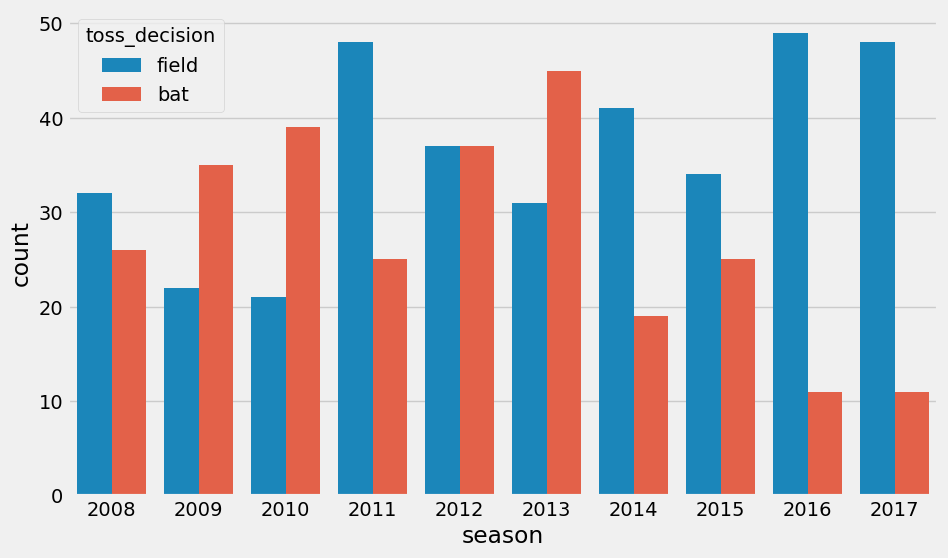

In [21]:
plt.subplots(figsize = (10,6))
sns.countplot(data = matches, x = 'season', hue = 'toss_decision')
plt.show()

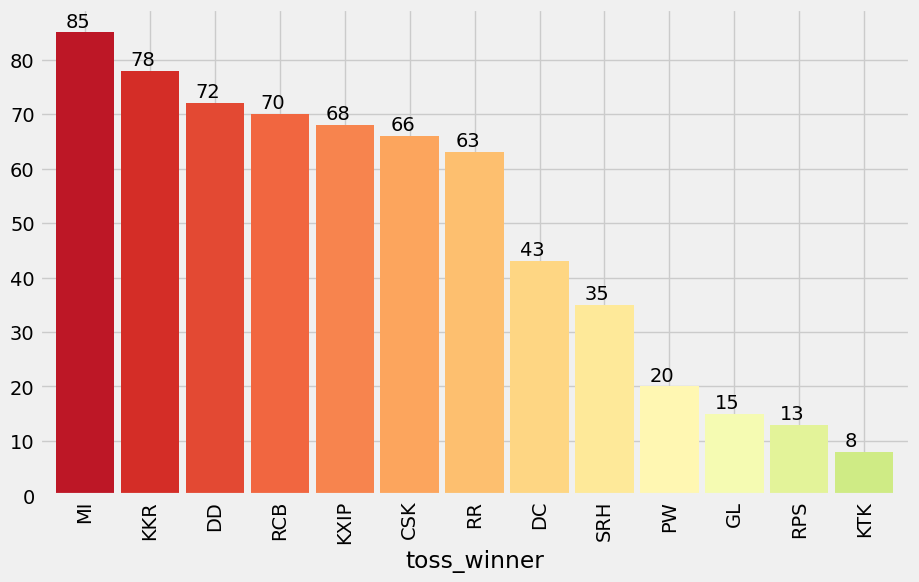

In [22]:
plt.subplots(figsize=(10, 6))

ax = matches['toss_winner'].value_counts().plot.bar(
    width=0.9,
    color=sns.color_palette('RdYlGn', 20)
)

for p in ax.patches:
    ax.annotate(
        format(p.get_height(), '.0f'),
        (p.get_x() + 0.15, p.get_height() + 1)
    )

plt.show()

<h2>Total Matches VS Win For Teams</h2>

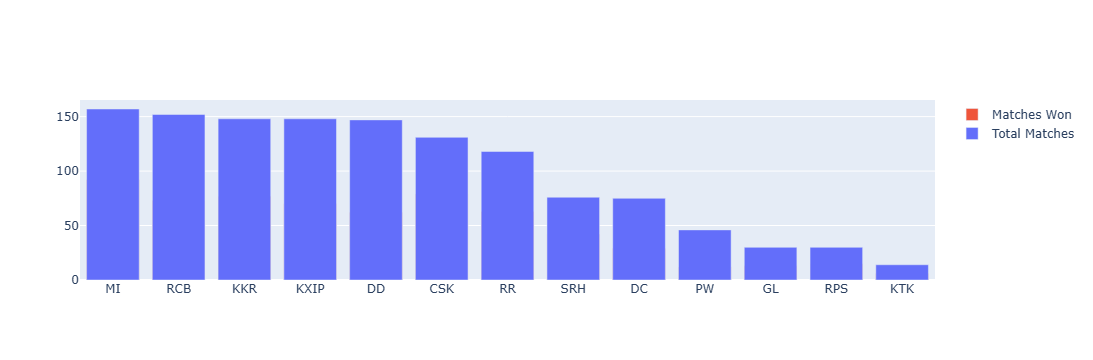

In [24]:
matches_played_byteams = pd.concat([
    matches['team1'],
    matches['team2']
])

matches_played_byteams = matches_played_byteams.value_counts().reset_index()

matches_played_byteams.columns = ['Teams', 'Total Matches']

matches_played_byteams['wins'] = (
    matches['winner'].value_counts()
    .reindex(matches_played_byteams['Teams'])
    .values
)

matches_played_byteams.set_index('Teams', inplace=True)

traces1 = go.Bar(
    x=matches_played_byteams.index,
    y=matches_played_byteams['Total Matches'],
    name='Total Matches',
    marker=dict(color='#636EFA')
)

traces2 = go.Bar(
    x=matches_played_byteams.index,
    y=matches_played_byteams['wins'],
    name='Matches Won',
    marker=dict(color='#EF553B')
)

data = [traces2, traces1]

layout = go.Layout(
    barmode='overlay'
)

fig = go.Figure(data=data, layout=layout)

py.iplot(fig, filename='stacked-bar')

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_31168\2551906882.py:18: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





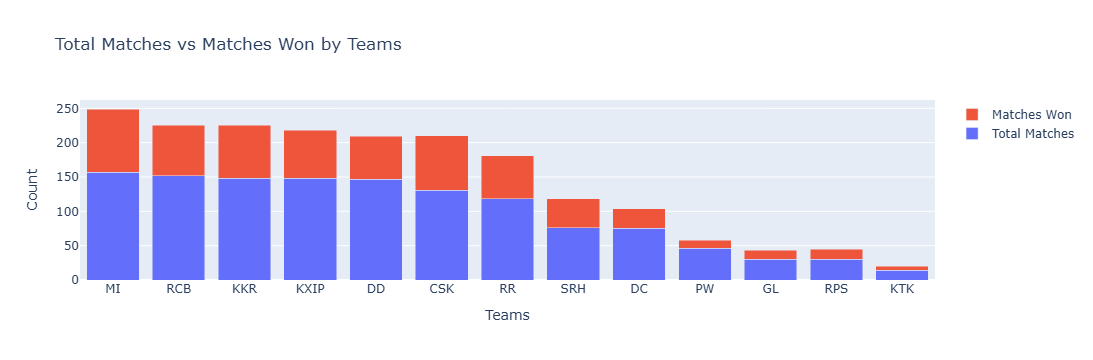

In [25]:
py.init_notebook_mode(connected=True)

matches_played_byteams = pd.concat([
    matches['team1'],
    matches['team2']
])

matches_played_byteams = matches_played_byteams.value_counts().reset_index()
matches_played_byteams.columns = ['Team', 'Total Matches']

wins = matches['winner'].value_counts().reset_index()
wins.columns = ['Team', 'Wins']

matches_played_byteams = matches_played_byteams.merge(
    wins, on='Team', how='left'
)

matches_played_byteams['Wins'].fillna(0, inplace=True)

matches_played_byteams.set_index('Team', inplace=True)

# Create stacked bar chart
trace1 = go.Bar(
    x=matches_played_byteams.index,
    y=matches_played_byteams['Total Matches'],
    name='Total Matches'
)

trace2 = go.Bar(
    x=matches_played_byteams.index,
    y=matches_played_byteams['Wins'],
    name='Matches Won'
)

data = [trace1, trace2]

layout = go.Layout(
    title='Total Matches vs Matches Won by Teams',
    xaxis=dict(title='Teams'),
    yaxis=dict(title='Count'),
    barmode='stack'
)

fig = go.Figure(data=data, layout=layout)

py.iplot(fig, filename='stacked-bar')



<h3>Is Toss Winner Also Match Winner</h3>

In [26]:
matches.columns

Index(['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2'],
      dtype='object')

In [27]:
matches.shape

(636, 17)

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_31168\2170786711.py:18: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



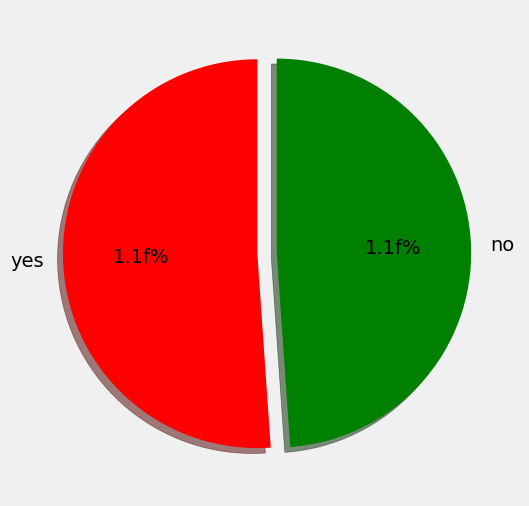

In [28]:
df = matches[matches['toss_winner'] == matches['winner']]

slices = [len(df), (636 - len(df))]

labels = ['yes', 'no']

plt.pie(slices, labels = labels,
        startangle = 90,
        shadow  = True,
        explode = (0.1, 0),
        autopct = '1.1f%%',
        colors = ['r','g'])

fig = plt.gcf()

fig.set_size_inches(6,6)

fig.show()

<h3>Matches Played Across Each Season</h3>

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_31168\678174304.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_31168\678174304.py:3: UserWarning:


The palette list has fewer values (6) than needed (10) and will cycle, which may produce an uninterpretable plot.



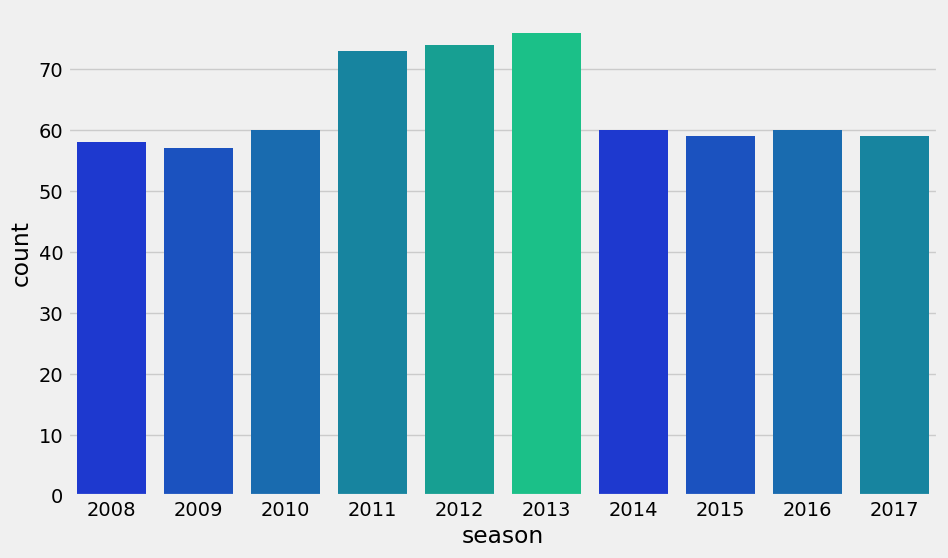

In [29]:
plt.subplots(figsize = (10,6))

sns.countplot(x = 'season', data = matches, palette = sns.color_palette('winter'))

plt.show()

<h3>Runs Across The Season</h3>

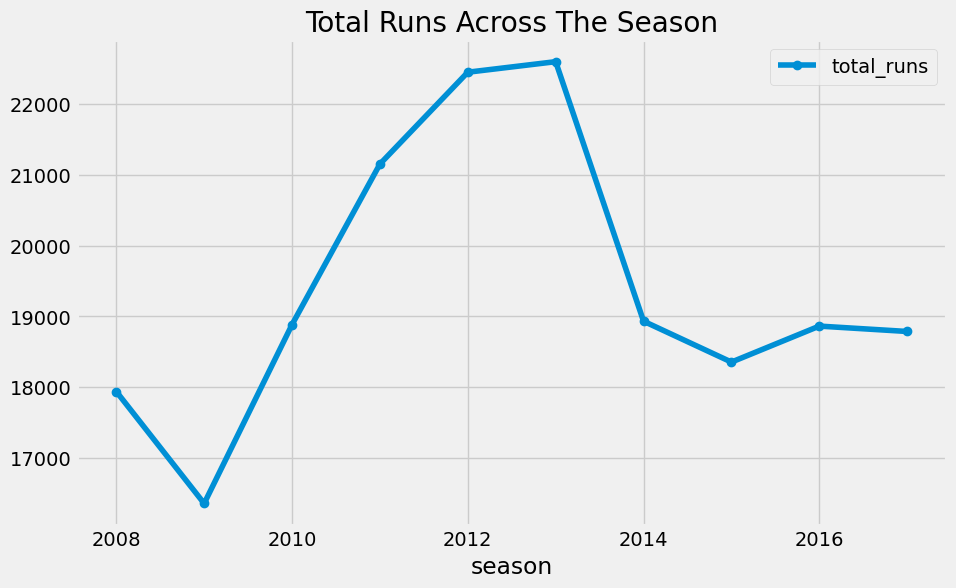

In [30]:
batsman = matches[['id', 'season']].merge(deliveries,
                              left_on = 'id',
                              right_on = 'match_id',
                              how = 'left').drop('id', axis = 1)


season = batsman.groupby(['season'])['total_runs'].sum().reset_index()

season.set_index('season').plot(marker = 'o')

plt.gcf().set_size_inches(10,6)

plt.title('Total Runs Across The Season')

plt.show()




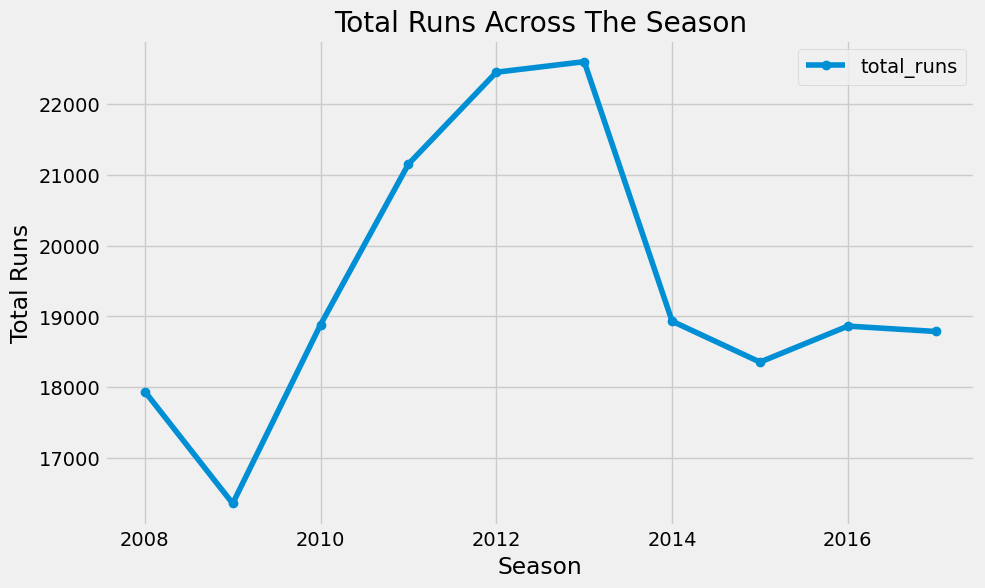

In [31]:
batsman = matches[['id', 'season']].merge(
    deliveries,
    left_on='id',
    right_on='match_id',
    how='left'
).drop('id', axis=1)

season = batsman.groupby(['season'])['total_runs'].sum().reset_index()

season.set_index('season').plot(marker='o')

plt.gcf().set_size_inches(10, 6)

plt.title('Total Runs Across The Season')
plt.xlabel('Season')
plt.ylabel('Total Runs')

plt.show()

<h3>Average runs per match in each season</h3>

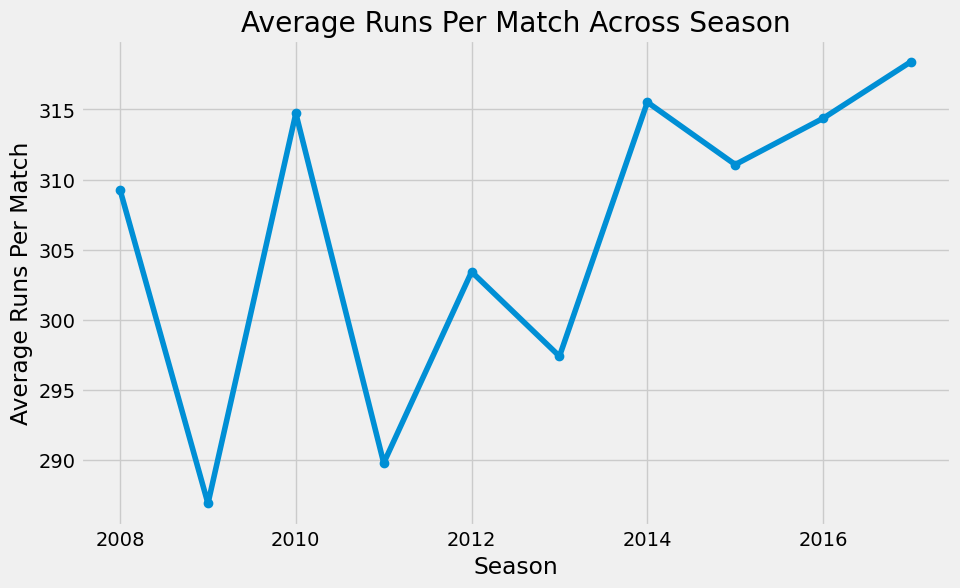

In [32]:
avgruns_each_season = matches.groupby(['season']).count().reset_index()

avgruns_each_season.rename(columns={'id': 'matches'}, inplace=True)

avgruns_each_season['total_runs'] = season['total_runs']

avgruns_each_season['average_runs_per_match'] = (
    avgruns_each_season['total_runs'] / avgruns_each_season['matches']
)

avgruns_each_season.set_index('season')['average_runs_per_match'].plot(marker='o')

plt.gcf().set_size_inches(10, 6)

plt.title('Average Runs Per Match Across Season')
plt.xlabel('Season')
plt.ylabel('Average Runs Per Match')

plt.show()

<h3>Sixes and Fours Across The Season</h3>

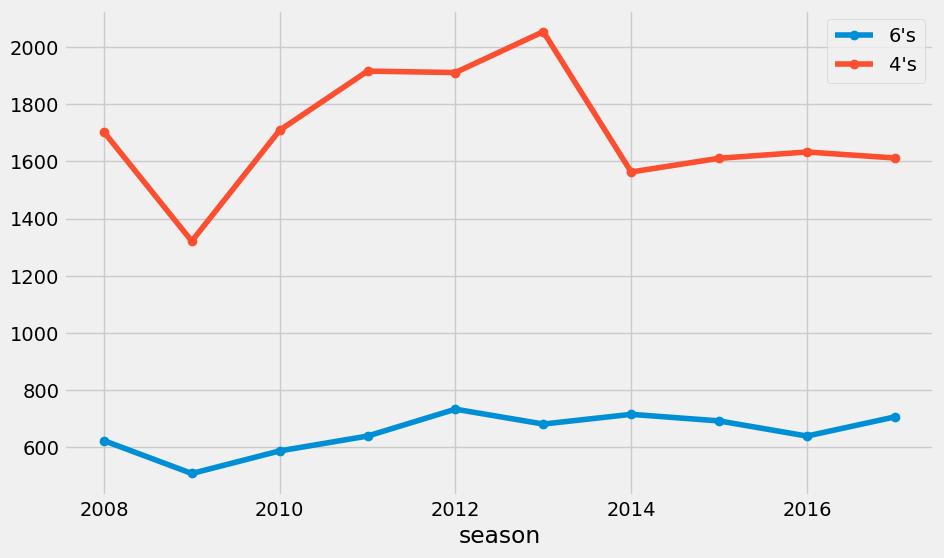

In [33]:
season_sixers = batsman.groupby('season')['batsman_runs'].agg(lambda x: (x == 6).sum()).reset_index()

season_fours = batsman.groupby('season')['batsman_runs'].agg(lambda x: (x == 4).sum()).reset_index()

season_sixers = season_sixers.merge(season_fours, left_on = 'season', right_on = 'season', how = 'left')

season_sixers.rename(columns = {'batsman_runs_x': "6's", 'batsman_runs_y': "4's"}, inplace = True)

season_sixers.set_index('season')[["6's","4's"]].plot(marker = 'o')

fig = plt.gcf()

fig.set_size_inches(10,6)

plt.show()

<h3>Runs Per Over By Team Across Season</h3>

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_31168\534227916.py:1: FutureWarning:

The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.



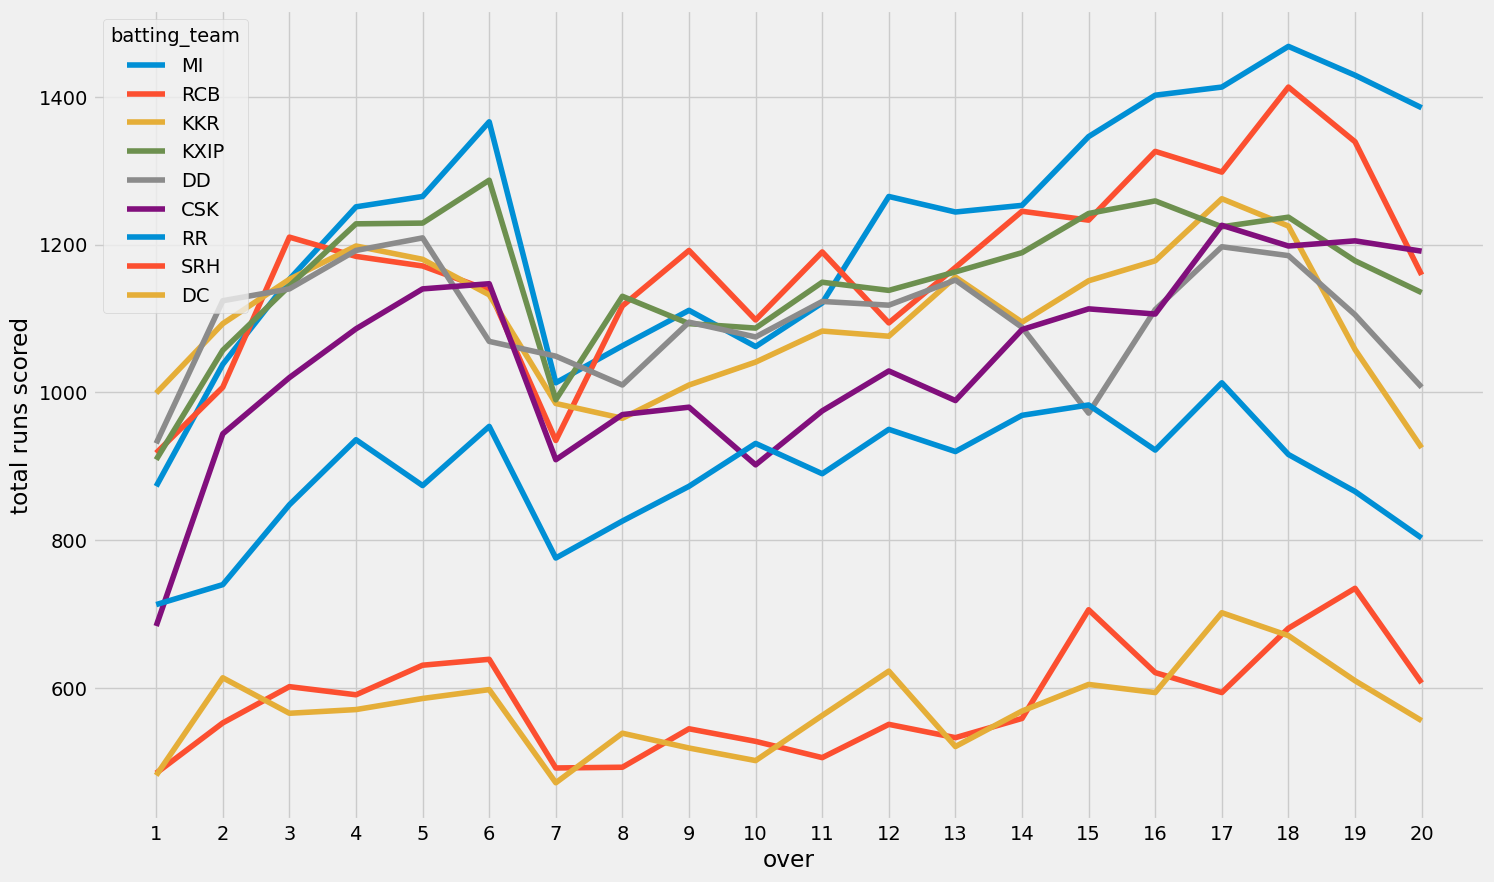

In [34]:
runs_per_over = deliveries.pivot_table(
    index=['over'],
    columns='batting_team',
    values='total_runs',
    aggfunc=sum
)

runs_per_over[
    matches_played_byteams[
        matches_played_byteams['Total Matches'] > 50
    ].index
].plot()

x = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
     11, 12, 13, 14, 15, 16, 17, 18, 19, 20]

plt.xticks(x)

plt.ylabel('total runs scored')

fig = plt.gcf()
fig.set_size_inches(16, 10)

plt.show()

<h2>Favorite Ground</h2>

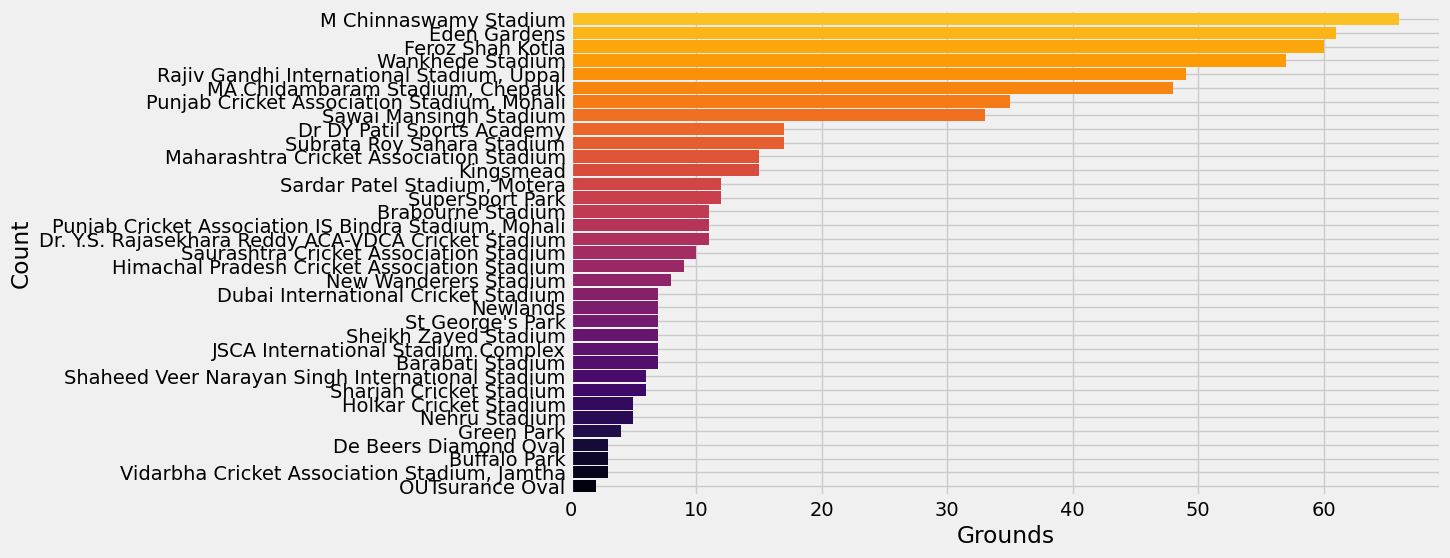

In [35]:
plt.subplots(figsize = (10,6))

ax = matches['venue'].value_counts().sort_values(ascending = True).plot.barh (width= 0.9, color = sns.color_palette('inferno', 40))

ax.set_xlabel('Grounds')

ax.set_ylabel('Count')

plt.show()

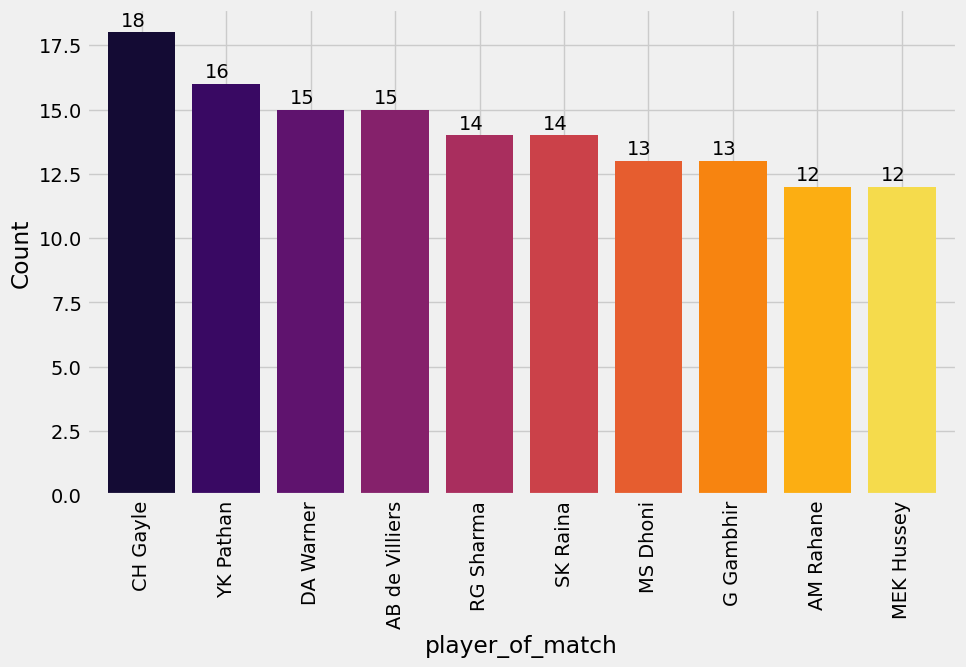

In [36]:
plt.subplots(figsize = (10,6))

ax = ax = matches['player_of_match'].value_counts().head(10).plot.bar(width = 0.8, color = sns.color_palette('inferno', 10))

ax.set_xlabel('player_of_match')

ax.set_ylabel('Count')

for p in ax.patches:
    ax.annotate(format(p.get_height()), (p.get_x() + 0.15, p.get_height() + 0.25))

plt.show()

<h2>Winning By Years</h2>

In [37]:
print('Winner By Years')

for i in range(2008, 2017):
    df = ((matches[matches['season'] == i]).iloc[-1])
    print(df[[1, 10]].values)

Winner By Years
[np.int64(2008) 'RR']
[np.int64(2009) 'DC']
[np.int64(2010) 'CSK']
[np.int64(2011) 'CSK']
[np.int64(2012) 'KKR']
[np.int64(2013) 'MI']
[np.int64(2014) 'KKR']
[np.int64(2015) 'MI']
[np.int64(2016) 'SRH']


C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_31168\3605615394.py:5: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



<h3>Total Matches With Super Over</h3>

In [38]:
print('\n Total Matches With Super Over', deliveries[deliveries['is_super_over'] == 1].match_id.nunique())


 Total Matches With Super Over 7


In [39]:
teams = ['MI', 'KKR', 'RCB', 'DC', 'CSK', 'RR', 'DD', 'GL', 'KXIP', 'SRH', 'RPS', 'KTK', 'PW']

play = deliveries[deliveries['is_super_over'] == 1].batting_team.unique()
play = list(play)

print("Teams who haven't ever played a super overs are: ", list(set(teams) - set(play)))

Teams who haven't ever played a super overs are:  ['RPS', 'KTK', 'PW', 'DC']


<h2>Favorite Umpires</h2>

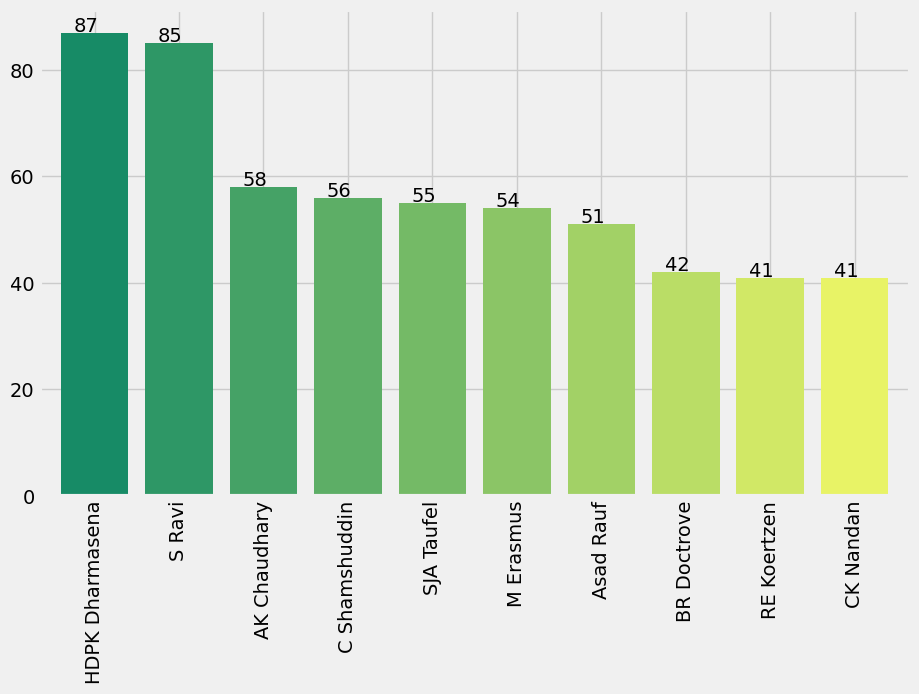

In [40]:
plt.subplots(figsize=(10, 6))

ump = pd.concat([matches['umpire1'], matches['umpire2']])

ax = ump.value_counts().head(10).plot.bar(
    width=0.8,
    color=sns.color_palette('summer', 10)
)

for p in ax.patches:
    ax.annotate(
        format(p.get_height(), '.0f'),
        (p.get_x() + 0.15, p.get_height() + 0.25)
    )

plt.show()

<h2>Team1 VS Team2</h2>

<h2>MI VS KKR</h2>

In [41]:
def team1_vs_team2(team1, team2):
    mt1 = matches[((matches['team1'] == team1) | (matches['team2'] == team1)) & ((matches['team1'] == team2) | (matches['team2'] == team2))]
    sns.countplot(x = 'season', hue = 'winner', data = mt1, palette = 'Set3')
    plt.xticks(rotation = 'vertical')
    leg = plt.legend(loc = 'upper center')
    fig = plt.gcf()
    fig.set_size_inches(10, 6)
    plt.show()
    
        

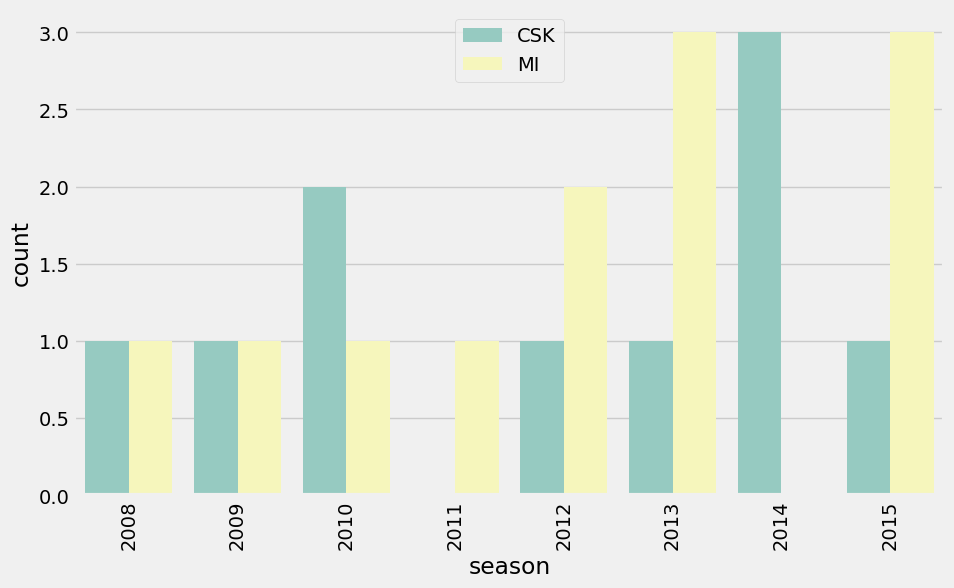

In [42]:
team1_vs_team2('CSK','MI')

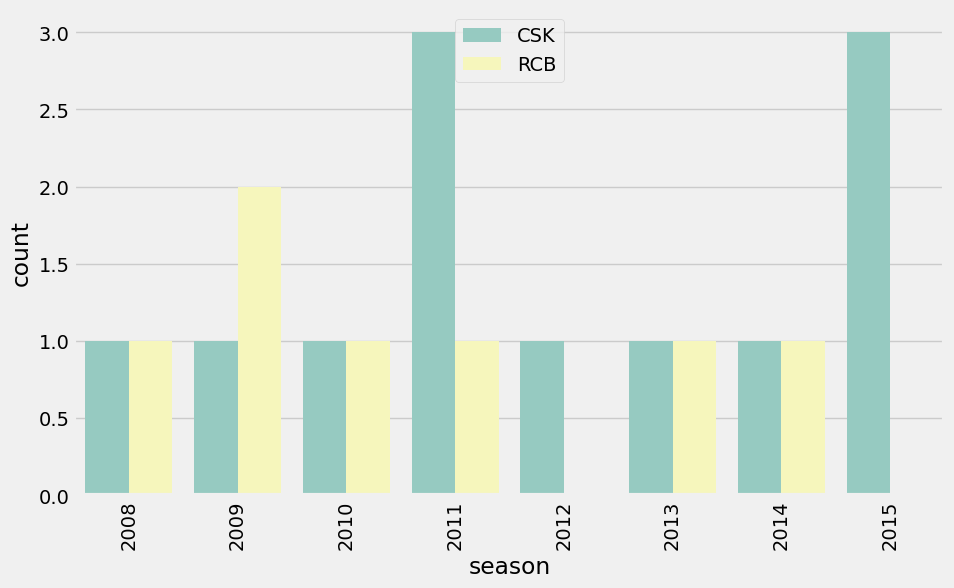

In [43]:
team1_vs_team2('CSK','RCB')

<h2>Matches Won By a Team Against Others Team</h2>

In [44]:
def comparator(team1):
    teams = ['SRH', 'MI', 'GL', 'RCB', 'KKR', 'DD', 'KXIP', 'CSK', 'RR', 'DC', 'KTK', 'PW', 'RPS']
    teams.remove(team1)
    opponents = teams.copy()
    mt1 = matches[((matches['team1'] == team1) | (matches['team2'] == team1))]

    for i in opponents:
        mask = (((mt1['team1'] == i) | (mt1['team2'] == i)) & ((mt1['team1'] == team1) | (mt1['team2'] == team1)))
        mt2 = mt1.loc[mask, 'winner'].value_counts().to_frame().T
        print(mt2)

In [45]:
comparator('MI')

winner  MI  SRH
count    5    5
winner  MI  GL
count    2   2
winner  MI  RCB
count   13    8
winner  MI  KKR
count   16    5
winner  MI  DD
count   11   9
winner  MI  KXIP
count   10    10
winner  MI  CSK
count   12   10
winner  MI  RR
count   10   6
winner  MI  DC
count    6   4
winner  KTK
count     1
winner  MI  PW
count    5   1
winner  RPS  MI
count     4   2


In [46]:
comparator('RCB')

winner  SRH  RCB
count     6    4
winner  MI  RCB
count   13    8
winner  RCB  GL
count     3   2
winner  KKR  RCB
count    11    9
winner  RCB  DD
count    12   6
winner  KXIP  RCB
count     12    8
winner  CSK  RCB
count    12    7
winner  RCB  RR
count     8   7
winner  DC  RCB
count    6    5
winner  RCB
count     2
winner  RCB
count     5
winner  RPS  RCB
count     2    2


<h2>Score Distribution</h2>

In [47]:
deliveries.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batsman', 'non_striker', 'bowler', 'is_super_over', 'wide_runs',
       'bye_runs', 'legbye_runs', 'noball_runs', 'penalty_runs',
       'batsman_runs', 'extra_runs', 'total_runs', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')

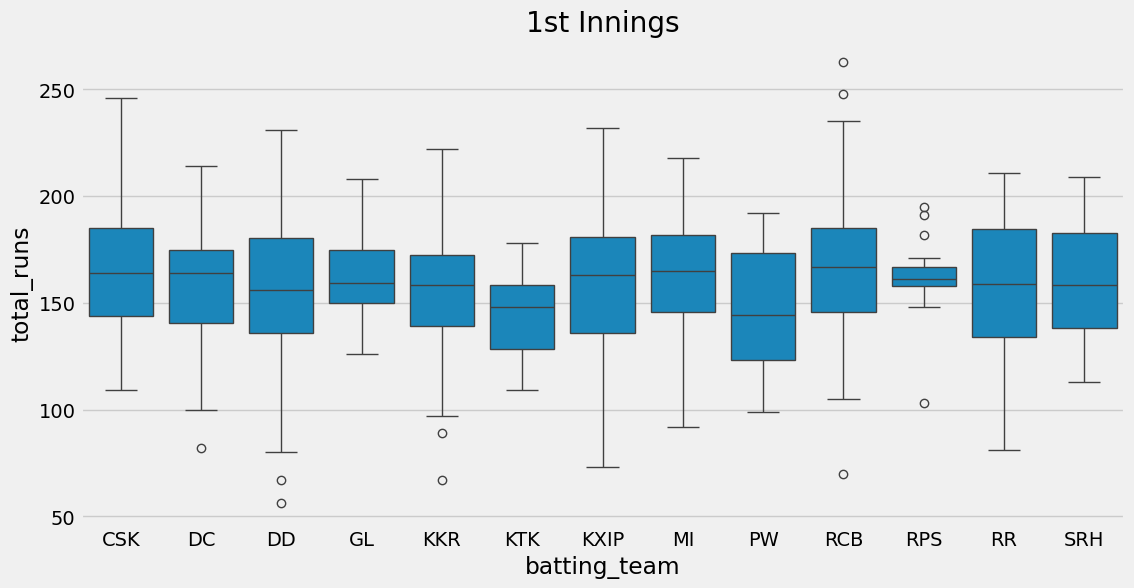

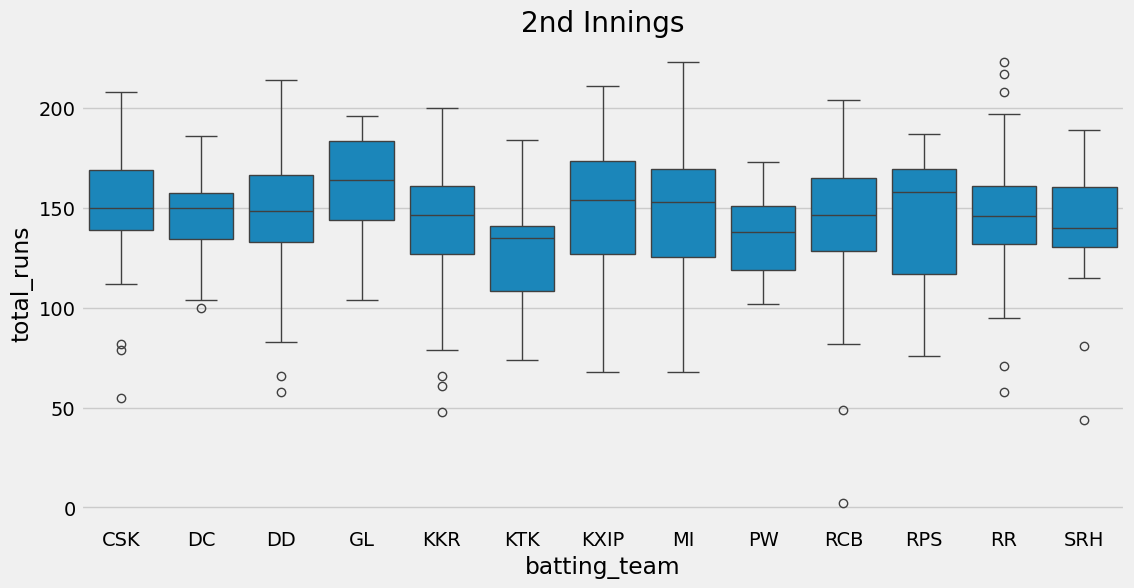

In [48]:
plt.subplots(figsize = (12,6))

xyz = deliveries.groupby(['match_id', 'inning', 'batting_team'])['total_runs'].sum().reset_index()

xyz.drop('match_id', axis = 1, inplace = True)

xyz = xyz.sort_values(by = ['batting_team', 'total_runs'], ascending = True)

score_1_inning = xyz[xyz['inning'] == 1]
score_2_inning = xyz[xyz['inning'] == 2]

sns.boxplot(x = 'batting_team', y = 'total_runs', data = score_1_inning)
plt.title('1st Innings')
plt.show()

sns.boxplot(x = 'batting_team', y = 'total_runs', data = score_2_inning)

fig = plt.gcf()
fig.set_size_inches(12,6)
plt.title('2nd Innings')
plt.show()

In [49]:
high_scores = deliveries.groupby(['match_id', 'inning', 'batting_team', 'bowling_team'])['total_runs'].sum().reset_index()

high_scores = high_scores[high_scores['total_runs'] >= 200]

high_scores.nlargest(10, 'total_runs')


,match_id,inning,batting_team,bowling_team,total_runs
829,411,1,RCB,PW,263
1250,620,1,RCB,GL,248
416,206,1,CSK,RR,246
122,61,1,CSK,KXIP,240
1134,562,1,RCB,MI,235
596,296,1,KXIP,RCB,232
522,259,1,DD,KXIP,231
981,486,1,KXIP,CSK,231
100,50,1,KXIP,MI,230
1170,580,1,RCB,SRH,227


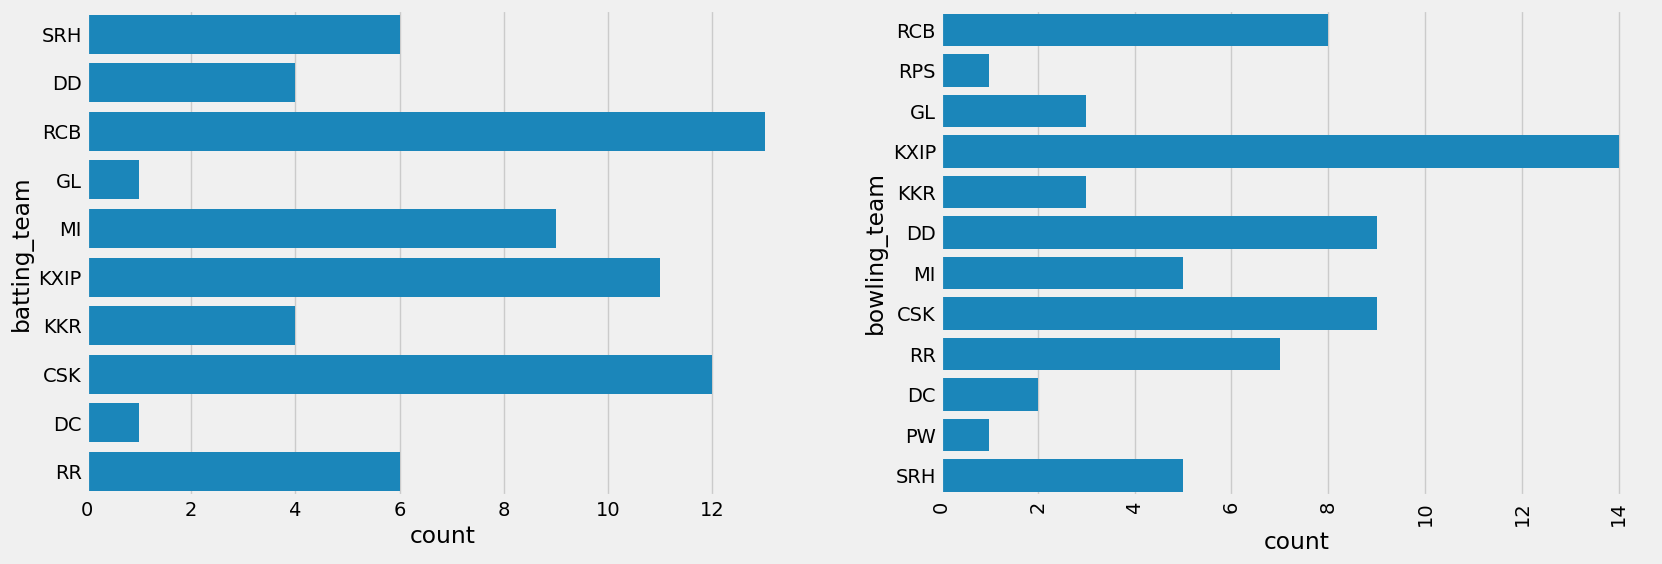

In [50]:
fig, ax = plt.subplots(1, 2)

sns.countplot(high_scores ['batting_team'], ax = ax[0])

sns.countplot(high_scores['bowling_team'], ax = ax[1])

plt.xticks(rotation = 90)

fig = plt.gcf()

fig.set_size_inches (18, 6)

plt.show()

In [51]:
print("Teams who have not ever scored 200+ runs:",
      list(set(teams) - set(high_scores['batting_team'])))

print("Teams who have not conceded over 200+ runs:",
      list(set(teams) - set(high_scores['bowling_team'])))

Teams who have not ever scored 200+ runs: ['RPS', 'KTK', 'PW']
Teams who have not conceded over 200+ runs: ['KTK']


<h2>Chance of Chasing 200+ Target</h2>

In [52]:
high_scores1 = deliveries.groupby(['match_id', 'inning'])['total_runs'].sum().reset_index()

scores = high_scores1.pivot(index = 'match_id', columns = 'inning', values = 'total_runs')

high_scores1 = high_scores1[high_scores1['inning'] == 1].copy()

high_scores1['is_score_chased'] = high_scores1['match_id'].map(
    (scores[2] > scores[1]).map({True: 'Yes', False: 'No'})
)

high_scores1 = high_scores1[high_scores1['total_runs'] >= 200]

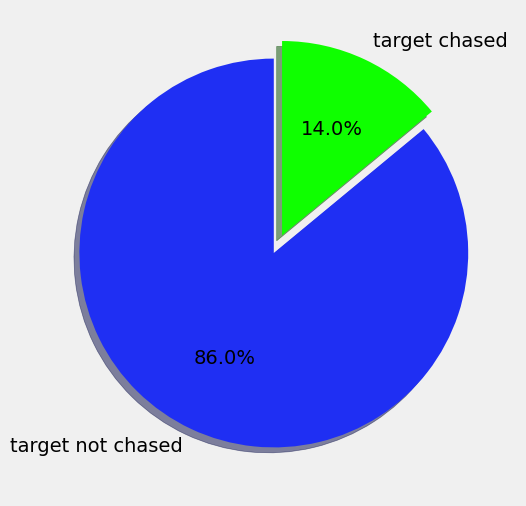

In [53]:
slices = high_scores1['is_score_chased'].map({'Yes': 1, 'No': 0}).value_counts()

labels = ['target not chased', 'target chased']

plt.pie(slices, labels = labels, colors = ['#1f2ff3', '#0fff00'], startangle = 90, shadow = True, explode = (0, 0.1), autopct = '%1.1f%%')

fig = plt.gcf()

fig.set_size_inches(6, 6)

plt.show()

In [54]:
deliveries.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batsman', 'non_striker', 'bowler', 'is_super_over', 'wide_runs',
       'bye_runs', 'legbye_runs', 'noball_runs', 'penalty_runs',
       'batsman_runs', 'extra_runs', 'total_runs', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')

In [55]:
print(high_scores.columns)

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'total_runs'], dtype='object')


<h2>Batsman Comparator</h2>

In [68]:
print(type(balls))


<class 'pandas.core.frame.DataFrame'>


In [69]:
print(type(balls))
print(balls.head())
print(balls.columns)

print(type(runs))
print(runs.head())
print(runs.columns)

<class 'pandas.core.frame.DataFrame'>
           ball_y  ball_x  ball_y  strike_rate  batsman_runs_x  batsman_runs_y
0  A Ashish Reddy     193     280   145.077720              15              16
1      A Chandila       7       4    57.142857               0               0
2        A Chopra      71      53    74.647887               0               7
3     A Choudhary      20      25   125.000000               1               1
4      A Flintoff      53      62   116.981132               2               5
Index(['ball_y', 'ball_x', 'ball_y', 'strike_rate', 'batsman_runs_x',
       'batsman_runs_y'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
          batsman  ball_y
0  A Ashish Reddy     280
1      A Chandila       4
2        A Chopra      53
3     A Choudhary      25
4      A Flintoff      62
Index(['batsman', 'ball_y'], dtype='object')


In [70]:
print(balls.head())
print(runs.head())

           ball_y  ball_x  ball_y  strike_rate  batsman_runs_x  batsman_runs_y
0  A Ashish Reddy     193     280   145.077720              15              16
1      A Chandila       7       4    57.142857               0               0
2        A Chopra      71      53    74.647887               0               7
3     A Choudhary      20      25   125.000000               1               1
4      A Flintoff      53      62   116.981132               2               5
          batsman  ball_y
0  A Ashish Reddy     280
1      A Chandila       4
2        A Chopra      53
3     A Choudhary      25
4      A Flintoff      62


In [71]:
print(type(balls))
print(type(runs))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


In [72]:
print(balls.head())
print(type(balls))


           ball_y  ball_x  ball_y  strike_rate  batsman_runs_x  batsman_runs_y
0  A Ashish Reddy     193     280   145.077720              15              16
1      A Chandila       7       4    57.142857               0               0
2        A Chopra      71      53    74.647887               0               7
3     A Choudhary      20      25   125.000000               1               1
4      A Flintoff      53      62   116.981132               2               5
<class 'pandas.core.frame.DataFrame'>


In [78]:
balls = balls.merge(runs, on = 'batsman', how = 'outer')

In [75]:
balls = deliveries.groupby(['batsman'])['ball'].count()

In [76]:
runs = deliveries.groupby(['batsman'])['batsman_runs'].sum().reset_index()

In [77]:
balls = balls.rename('ball_x').reset_index()

In [66]:
print(balls.columns.tolist())

print(balls[['ball_x', 'ball_y']].head())

print(type(balls['ball_x']))
print(type(balls['ball_y']))


['ball_y', 'ball_x', 'ball_y', 'strike_rate', 'batsman_runs_x', 'batsman_runs_y']
   ball_x          ball_y  ball_y
0     193  A Ashish Reddy     280
1       7      A Chandila       4
2      71        A Chopra      53
3      20     A Choudhary      25
4      53      A Flintoff      62
<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>


In [79]:
balls.rename({'ball': 'ball_x' , 'batsman' : 'ball_y'}, axis = 1, inplace = True)

In [80]:
balls = deliveries[(deliveries['wide_runs'] == 0) & (deliveries['noball_runs'] == 0)].groupby('batsman').size().reset_index(name = 'ball_x')

runs = deliveries.groupby('batsman')['batsman_runs'].sum().reset_index(name = 'ball_y')

balls = balls.merge(runs, on = 'batsman', how = 'outer')

fours = deliveries.groupby('batsman')['batsman_runs'].agg(lambda x: (x == 4).sum()).reset_index()

sixers = deliveries.groupby('batsman')['batsman_runs'].agg(lambda x: (x == 6).sum()).reset_index()

balls['strike_rate'] = balls['ball_y'] / balls['ball_x'].replace(0, np.nan)*100

balls = balls.merge(sixers, left_on = 'batsman', right_on = 'batsman', how = 'outer')

balls = balls.merge(fours, left_on = 'batsman', right_on = 'batsman', how = 'outer')

compare = deliveries.groupby(['match_id', 'batsman', 'batting_team'])['batsman_runs'].sum().reset_index()

compare = compare.groupby(['batsman', 'batting_team'])['batsman_runs'].max().reset_index()

compare

,batsman,batting_team,batsman_runs
0,A Ashish Reddy,DC,10
1,A Ashish Reddy,SRH,36
2,A Chandila,RR,4
3,A Chopra,KKR,24
4,A Choudhary,RCB,15
...,...,...,...
778,Yuvraj Singh,RCB,83
779,Yuvraj Singh,SRH,70
780,Z Khan,DD,4
781,Z Khan,MI,23


In [81]:
print(balls.columns.tolist())

['batsman', 'ball_x', 'ball_y', 'strike_rate', 'batsman_runs_x', 'batsman_runs_y']


In [82]:
print(balls.columns.tolist())
print(balls.head())

['batsman', 'ball_x', 'ball_y', 'strike_rate', 'batsman_runs_x', 'batsman_runs_y']
          batsman  ball_x  ball_y  strike_rate  batsman_runs_x  batsman_runs_y
0  A Ashish Reddy     193     280   145.077720              15              16
1      A Chandila       7       4    57.142857               0               0
2        A Chopra      71      53    74.647887               0               7
3     A Choudhary      20      25   125.000000               1               1
4      A Flintoff      53      62   116.981132               2               5


In [83]:
compare.groupby(['batsman', 'batting_team'])['batsman_runs'].max()

batsman         batting_team
A Ashish Reddy  DC              10
                SRH             36
A Chandila      RR               4
A Chopra        KKR             24
A Choudhary     RCB             15
                                ..
Yuvraj Singh    RCB             83
                SRH             70
Z Khan          DD               4
                MI              23
                RCB             21
Name: batsman_runs, Length: 783, dtype: int64

In [84]:
print(balls.columns.tolist())
print(fours.columns.tolist())
print(sixers.columns.tolist())

['batsman', 'ball_x', 'ball_y', 'strike_rate', 'batsman_runs_x', 'batsman_runs_y']
['batsman', 'batsman_runs']
['batsman', 'batsman_runs']


In [85]:
fours = deliveries.groupby('batsman')['batsman_runs'].agg(lambda x: (x == 4).sum()).reset_index()

sixers = deliveries.groupby('batsman')['batsman_runs'].agg(lambda x: (x == 6).sum()).reset_index()

fours.rename({'batsman_runs': "4's"}, axis = 1, inplace = True)

sixers.rename({'batsman_runs': "6's"}, axis = 1, inplace = True)

balls = balls.drop(columns = ["4's", "6's"], errors = 'ignore')

balls = balls.merge(fours, on = 'batsman', how = 'left')

balls = balls.merge(sixers, on = 'batsman', how = 'left')

In [86]:
def batsman_comparator(stat1, stat2, batsman1, batsman2):
    sns.FacetGrid(balls, height = 8).map(plt.scatter, stat1, stat2, alpha = 0.5)

    bats1 = balls[balls['batsman'].str.contains(batsman1)].sort_values(by = stat1, ascending = False)
    bats2 = balls[balls['batsman'].str.contains(batsman2)].sort_values(by = stat1, ascending = False)

    plt.scatter(bats1[stat1], bats1[stat2] - 1, s = 75, c = '#55ff33')
    plt.text(x = bats1[stat1].values[0], y = bats1[stat2].values[0], s = batsman1,
             fontsize = 10, weight = 'bold', color = '#f46d43')

    plt.scatter(bats2[stat1], bats2[stat2], s = 75, c = '#f73545')
    plt.text(x = bats2[stat1].values[0], y = bats2[stat2].values[0] + 1, s = batsman2,
             fontsize = 10, weight = 'bold', color = '#ff58fd')

    plt.gcf().set_size_inches(15, 10)
    plt.title('Batsman Comparator', size = 25)
    plt.show()





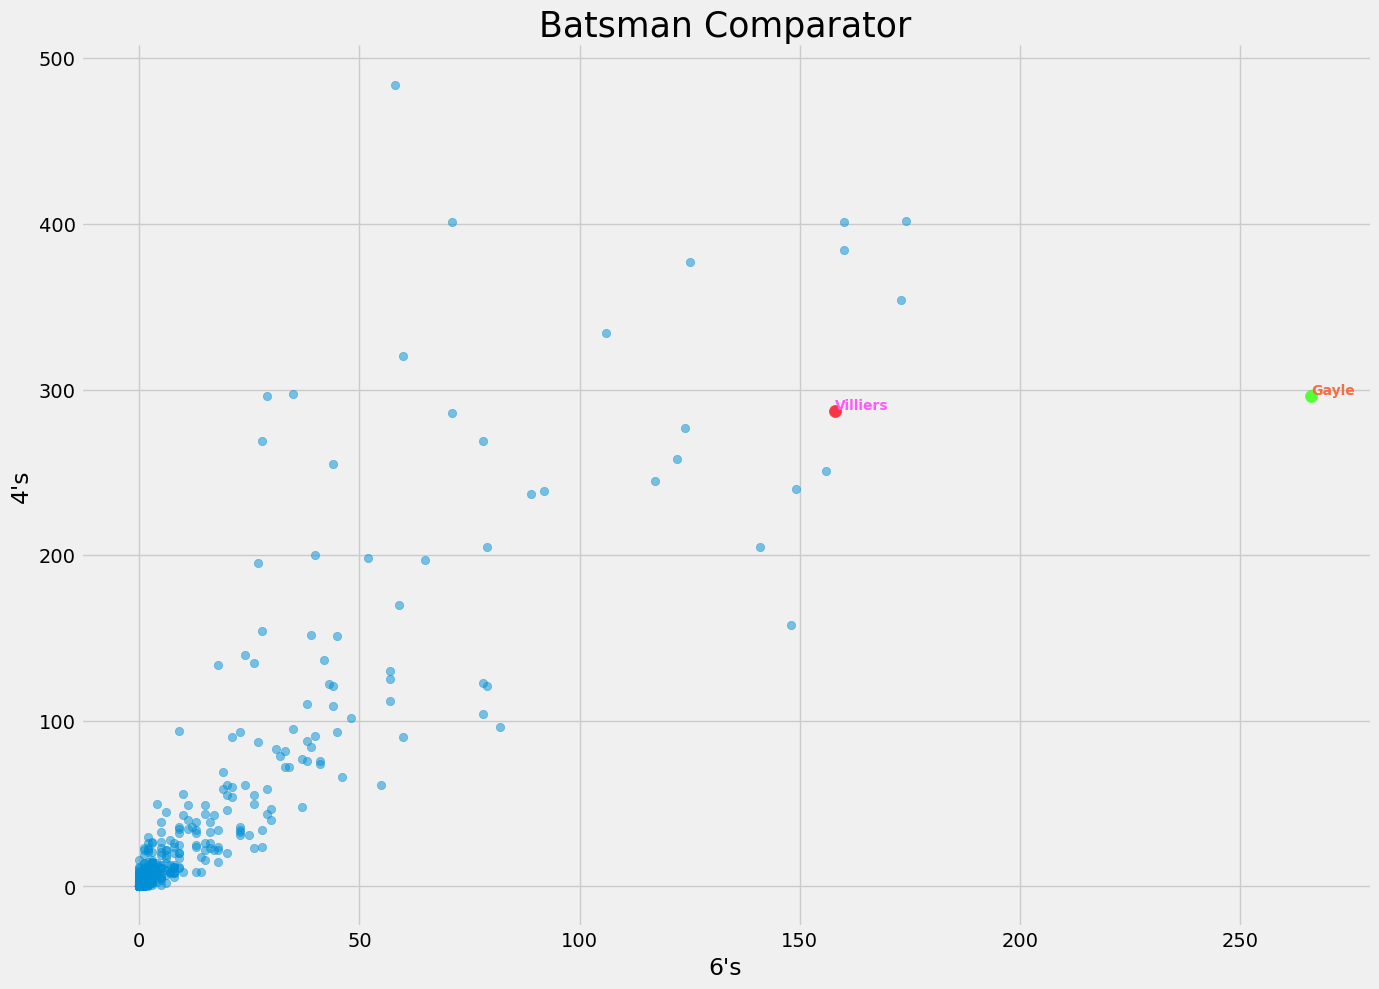

In [87]:
batsman_comparator("6's", "4's", "Gayle", "Villiers")

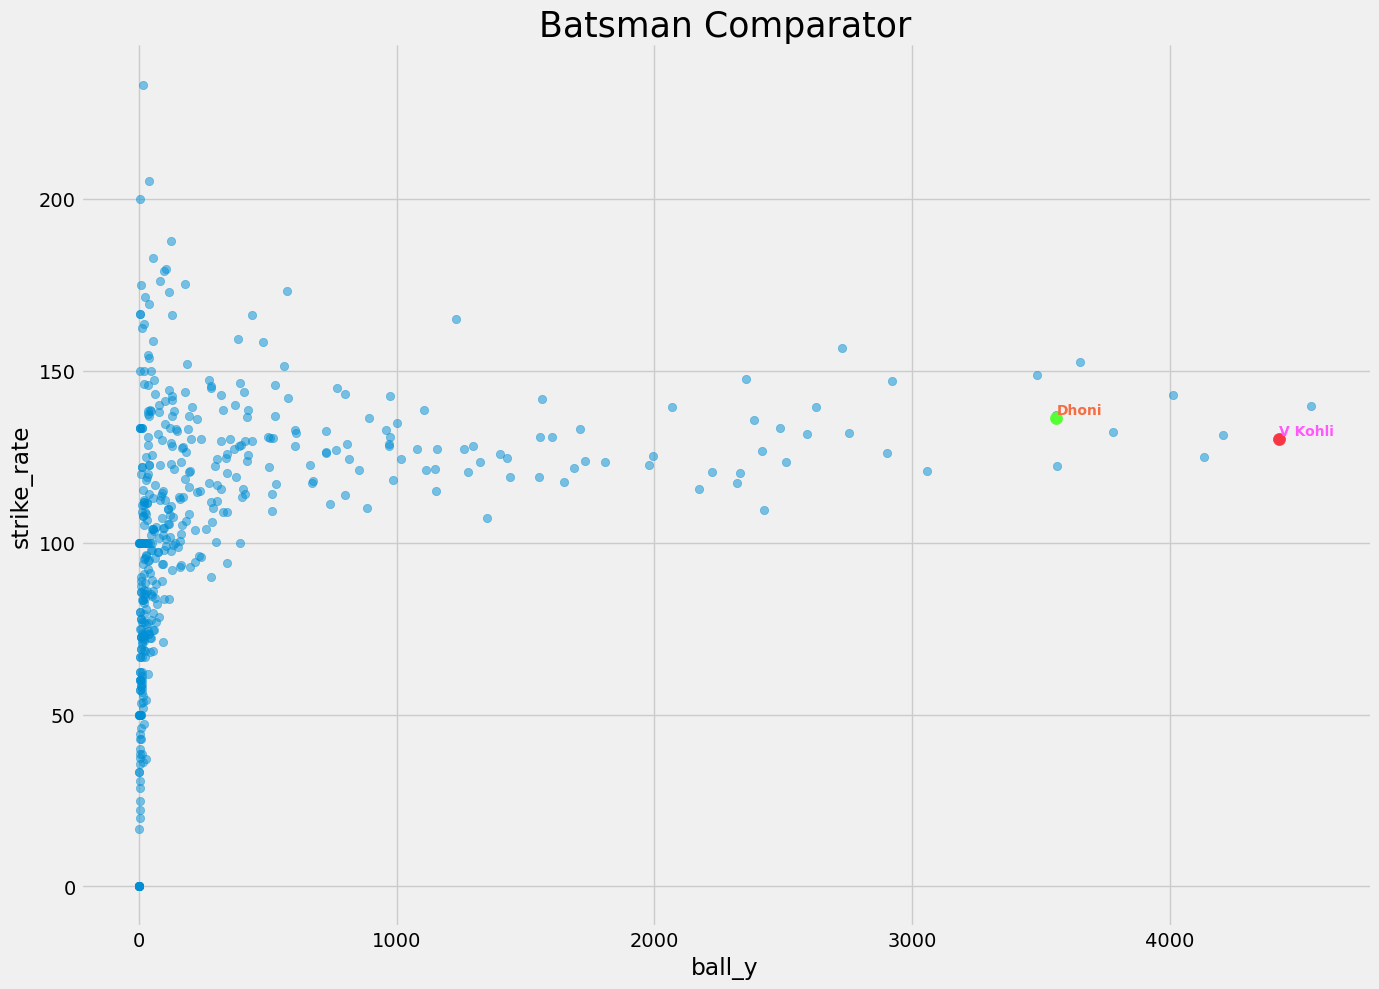

In [88]:
batsman_comparator("ball_y", "strike_rate", "Dhoni", "V Kohli")

<h1>Top  Batsman</h1>

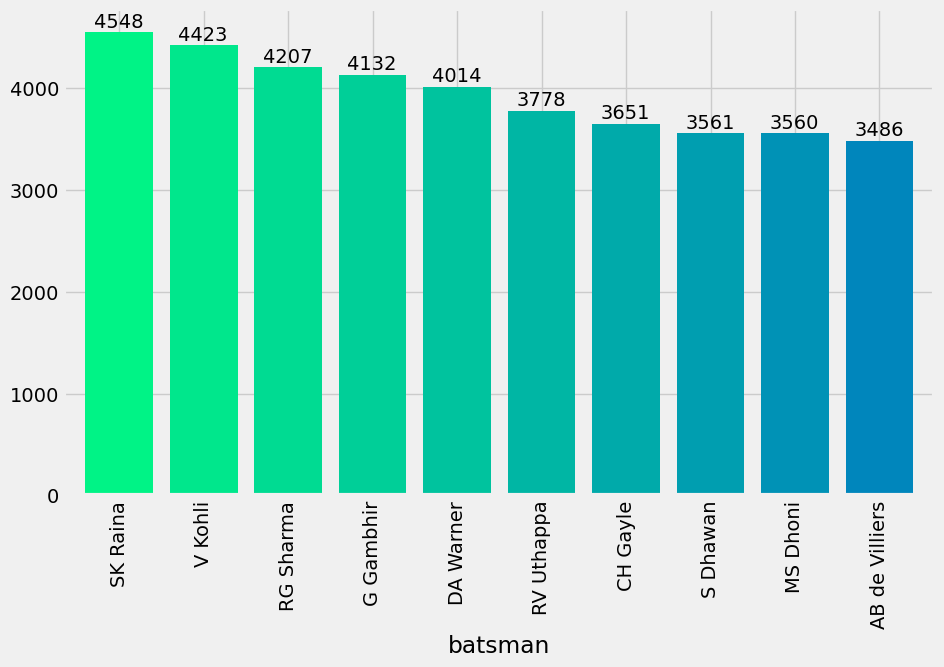

In [89]:
plt.subplots (figsize = (10, 6))

max_runs = deliveries.groupby(['batsman'])['batsman_runs'].sum()

ax = max_runs.sort_values (ascending = False) [:10].plot.bar(width = 0.8, color = sns.color_palette("winter_r", 20))

for p in ax.patches:
    ax.annotate(format(p.get_height()), (p.get_x() + 0.1, p.get_height() + 50))

plt.show()

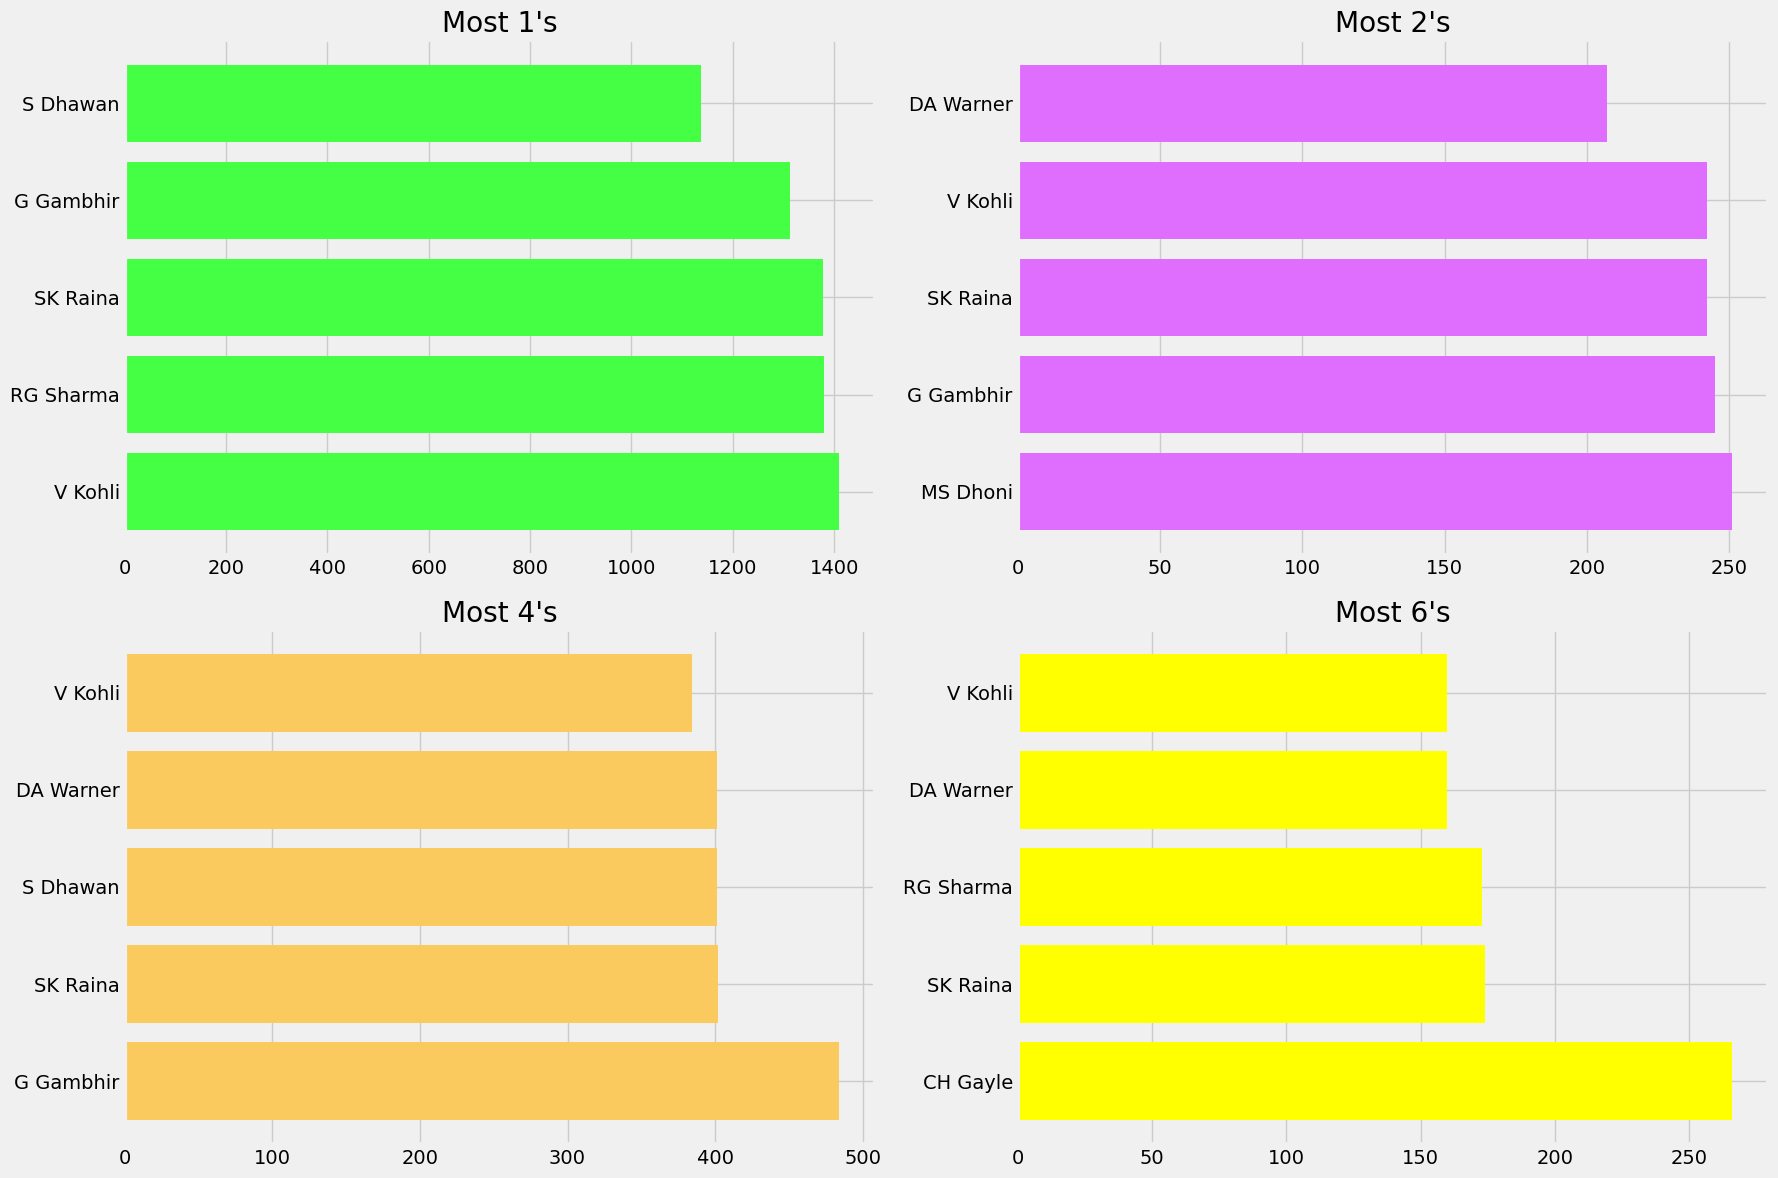

In [90]:
toppers = deliveries.groupby(['batsman', 'batsman_runs'])['total_runs'].count().reset_index()

toppers = toppers.pivot_table(index = "batsman", columns = "batsman_runs", values = "total_runs", fill_value = 0)

fig, ax = plt.subplots(2, 2, figsize = (18, 12))

toppers[1].sort_values(ascending = False)[:5].plot(kind = 'barh', ax = ax[0,0], color = "#45ff45", width = 0.8)
ax[0,0].set_title("Most 1's")
ax[0,0].set_ylabel("")

toppers[2].sort_values(ascending = False)[:5].plot(kind = 'barh', ax = ax[0,1], color = "#df6dfd", width = 0.8)
ax[0,1].set_title("Most 2's")
ax[0,1].set_ylabel("")

toppers[4].sort_values(ascending = False)[:5].plot(kind = 'barh', ax = ax[1,0], color = "#fbca5f", width = 0.8)
ax[1,0].set_title("Most 4's")
ax[1,0].set_ylabel("")

toppers[6].sort_values(ascending = False)[:5].plot(kind = 'barh', ax = ax[1,1], color = "#ffff00", width = 0.8)
ax[1,1].set_title("Most 6's")
ax[1,1].set_ylabel("")

plt.tight_layout()
plt.show()

<h1>Top Individual Scores</h1>

In [91]:
top_scores = deliveries.groupby(['match_id', 'batsman', 'batting_team'])['batsman_runs'].sum().reset_index()

top_scores.sort_values('batsman_runs', ascending = 0).head(10)

top_scores.nlargest(10,'batsman_runs')

,match_id,batsman,batting_team,batsman_runs
6200,411,CH Gayle,RCB,175
900,60,BB McCullum,KKR,158
8426,562,AB de Villiers,RCB,133
9257,620,AB de Villiers,RCB,129
5585,372,CH Gayle,RCB,128
3135,206,M Vijay,CSK,127
529,36,DA Warner,SRH,126
7752,516,V Sehwag,KXIP,122
3686,243,PC Valthaty,KXIP,120
4223,279,V Sehwag,DD,119


<h2>Individual Scores by Top Batsman each Innings</h2>

C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning:

7.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning:

24.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning:

20.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning:

20.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning:

24.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

C:\Use

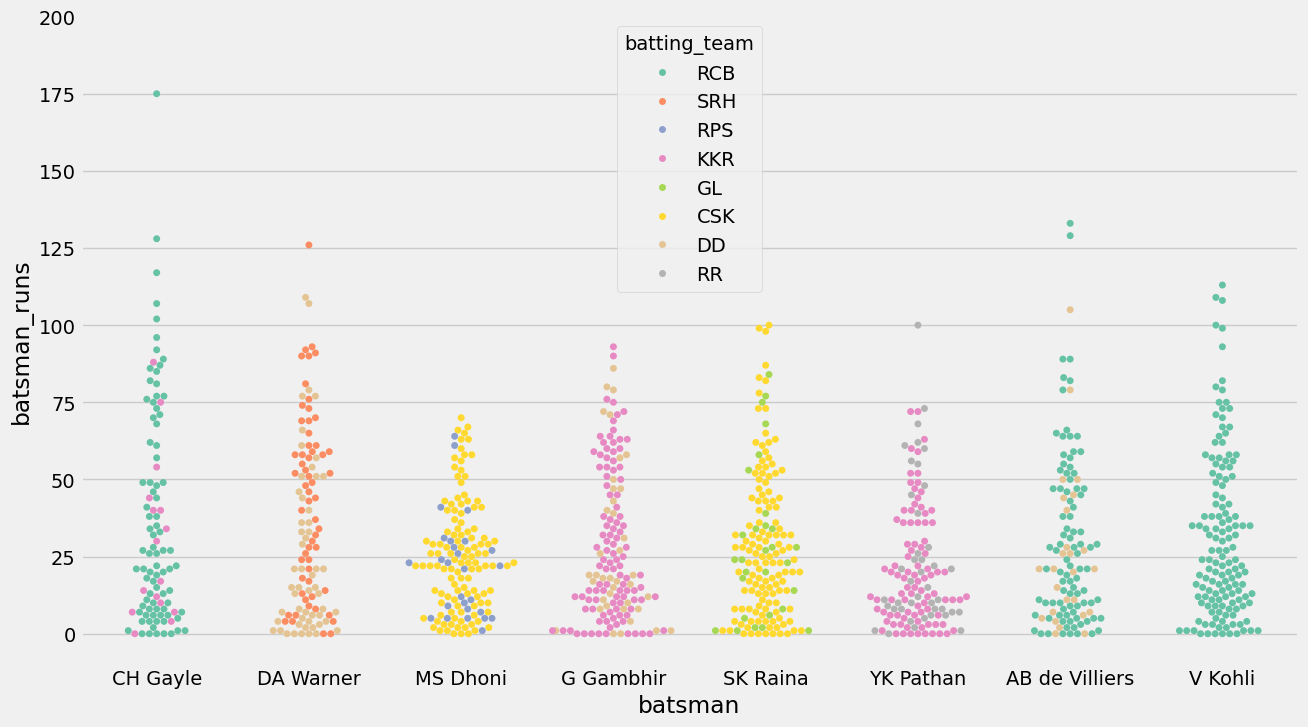

In [92]:
swarm = ['CH Gayle', 'V Kohli', 'G Gambhir', 'SK Raina', 'YK Pathan', 'MS Dhoni', 'AB de Villiers', 'DA Warner']
scores = deliveries.groupby(['match_id', 'batsman', 'batting_team'])['batsman_runs'].sum().reset_index()

scores = scores[top_scores['batsman'].isin(swarm)]

sns.swarmplot(x ='batsman', y ='batsman_runs', data = scores, hue = 'batting_team', palette = 'Set2')

fig = plt.gcf()

fig.set_size_inches(14, 8)

plt.ylim(-10, 200)

plt.show()

<h2>Runs Scored By Batsman Across Season</h2>

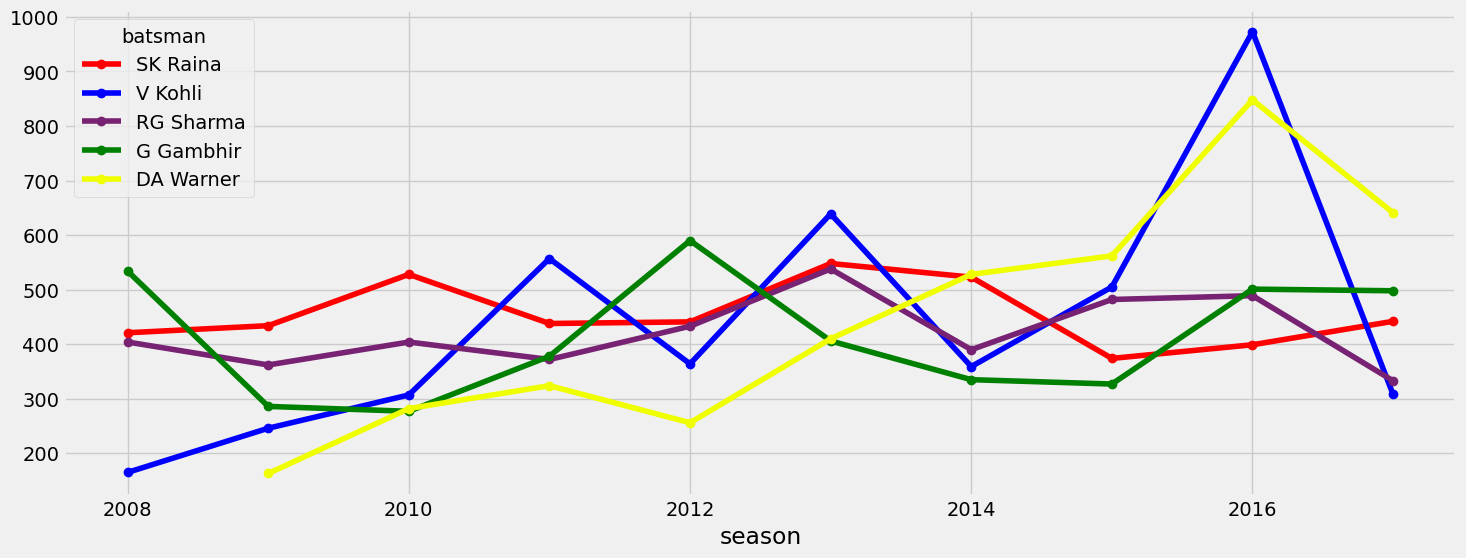

In [93]:
batsmen = deliveries.merge(matches[['id', 'season']], left_on = 'match_id', right_on = 'id', how = 'left')

a = batsmen.groupby(['season', 'batsman'])['batsman_runs'].sum().reset_index()

a = a.groupby(['season', 'batsman'])['batsman_runs'].sum().unstack().T

a['Total'] = a.sum(axis = 1)

a = a.sort_values(by = 'Total', ascending = 0)[:5]

a.drop('Total', axis = 1, inplace = True)

a.T.plot(color = ['red', 'blue', '#772272', 'green', '#f0ff00'], marker = 'o')

fig = plt.gcf()

fig.set_size_inches(16, 6)

plt.show()

<h2>Frequency Of Scores</h2>

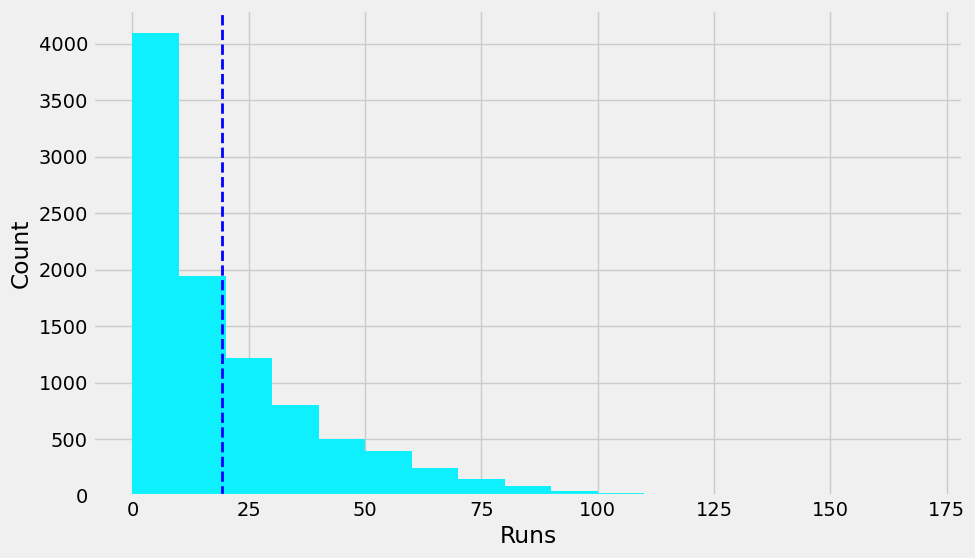

In [94]:
plt.subplots(figsize = (10,6))
bins = range(0, 180, 10)
plt.hist(top_scores['batsman_runs'], bins, histtype = 'bar', rwidth = 1.2, color = '#0ff0ff')
plt.xlabel('Runs')
plt.ylabel('Count')
plt.axvline(top_scores['batsman_runs'].mean(), color = 'b', linestyle = 'dashed', linewidth = 2)


plt.plot()
plt.show()

<h2>Orange Caps Each Season</h2>

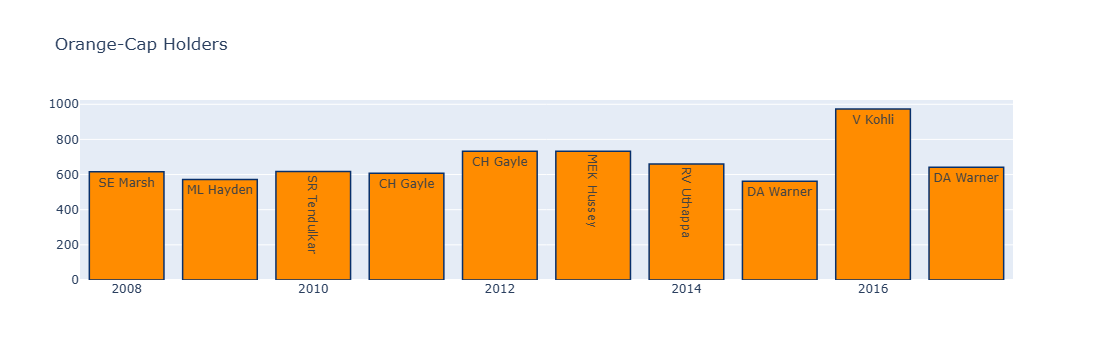

In [95]:
orange = matches[['id', 'season']]

orange = orange.merge(deliveries, left_on = 'id', right_on = 'match_id', how = 'left')

orange = orange.groupby(['season', 'batsman'])['batsman_runs'].sum().reset_index()

orange = orange.sort_values('batsman_runs', ascending = 0)

orange = orange.drop_duplicates(subset = ['season'], keep = 'first')

orange = orange.sort_values(by = 'season')


trace1 = go.Bar(
    x = orange['season'].values,
    y = orange['batsman_runs'].values,
    name = 'Orange Cap',
    text = orange['batsman'].values,
    marker = dict(
        color = 'rgb(255, 140, 0)',
        line = dict(
            color = 'rgb(8, 48, 107)',
            width = 1.5
        )
    ),
    opacity = 1
)

layout = go.Layout(
    title = "Orange-Cap Holders",
)

data = [trace1]

fig = go.Figure(data = data, layout = layout)

py.iplot(fig, filename = 'stacked-bar')

<h2>Top Bowlers</h2>

<h5>Highest Wicket Taker</h5>

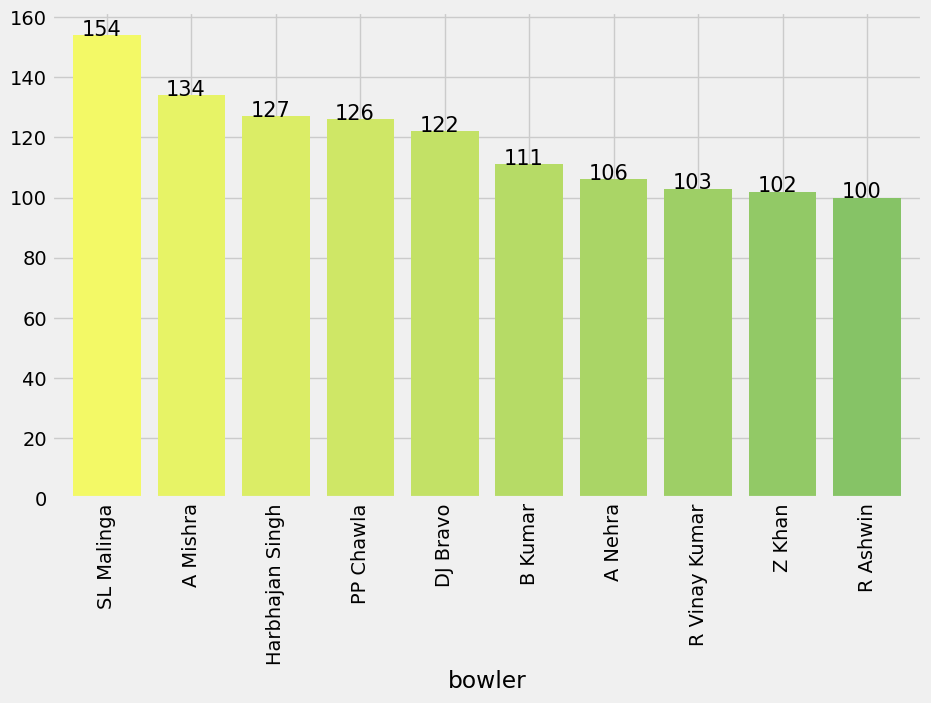

In [96]:
plt.subplots(figsize = (10,6))
dismissal_kinds = ['bowled', 'caught', 'lbw', 'stumped', 'caught and bowled', 'hit wicket']
ct = deliveries[deliveries['dismissal_kind'].isin (dismissal_kinds)]

ax = ct['bowler'].value_counts()[:10].plot.bar(width = 0.8, color = sns.color_palette('summer_r', 20))

for p in ax.patches:
    ax.annotate(format(p.get_height()), (p.get_x() + 0.10, p.get_height()), fontsize = 15)

plt.show()

<h4>Maximum Overs</h4>

In [97]:
eco = deliveries.groupby(['bowler']).sum(numeric_only = True)

eco['total_balls'] = deliveries['bowler'].value_counts()

eco['overs'] = (eco['total_balls']//6)

eco[eco['overs'] > 200].sort_values(by = 'overs', ascending = 0) ['overs'].head(5).reset_index()

,bowler,overs
0,Harbhajan Singh,498
1,A Mishra,450
2,SL Malinga,449
3,P Kumar,439
4,PP Chawla,432


In [98]:
eco['economy'] = (eco['total_runs'] / (eco['overs']))

eco[eco['overs']>300].sort_values('economy') [:10].economy.reset_index()

,bowler,economy
0,SP Narine,6.395706
1,R Ashwin,6.493639
2,DW Steyn,6.615599
3,SL Malinga,6.757238
4,Harbhajan Singh,6.933735
5,B Kumar,7.046784
6,A Mishra,7.344444
7,PP Ojha,7.404321
8,Z Khan,7.546174
9,P Kumar,7.612756


In [99]:
# Calculate total runs given by each bowler
bowlers = deliveries.groupby('bowler').sum(numeric_only = True).reset_index()

# Calculate balls bowled by each bowler
bowl = deliveries['bowler'].value_counts().reset_index()

bowl.columns = ['bowler', 'balls']

bowl['index'] = range(1, len(bowl) + 1)

bowl['bowler'] = bowl['bowler'].astype(str)

bowlers['bowler'] = bowlers['bowler'].astype(str)

bowlers = bowlers.merge(bowl, on = 'bowler', how = 'left')


# Select required columns
bowlers = bowlers[['bowler', 'total_runs', 'balls']]

bowlers.rename({'total_runs': 'runs_given'}, axis = 1, inplace = True)

# Calculate overs
bowlers['overs'] = bowlers['balls'] / 6


# Calculate wickets
dismissal_kinds = ['bowled', 'caught', 'lbw', 'stumped', 'caught and bowled', 'hit wicket']

ct = deliveries[deliveries['dismissal_kind'].isin(dismissal_kinds)]

ct = ct['bowler'].value_counts()[:20].reset_index()

ct.columns = ['bowler', 'wickets']

ct['bowler'] = ct['bowler'].astype(str)

bowlers = bowlers.merge(ct, on = 'bowler', how = 'left').dropna()


# Calculate economy rate
bowlers['economy'] = bowlers['runs_given'] / bowlers['overs']

bowlers.head()

,bowler,runs_given,balls,overs,wickets,economy
5,A Mishra,3305,2703,450.500000,134.0,7.336293
7,A Nehra,2537,1974,329.000000,106.0,7.711246
50,B Kumar,2410,2054,342.333333,111.0,7.039922
88,DJ Bravo,2815,2110,351.666667,122.0,8.004739
103,DW Steyn,2375,2159,359.833333,92.0,6.600278


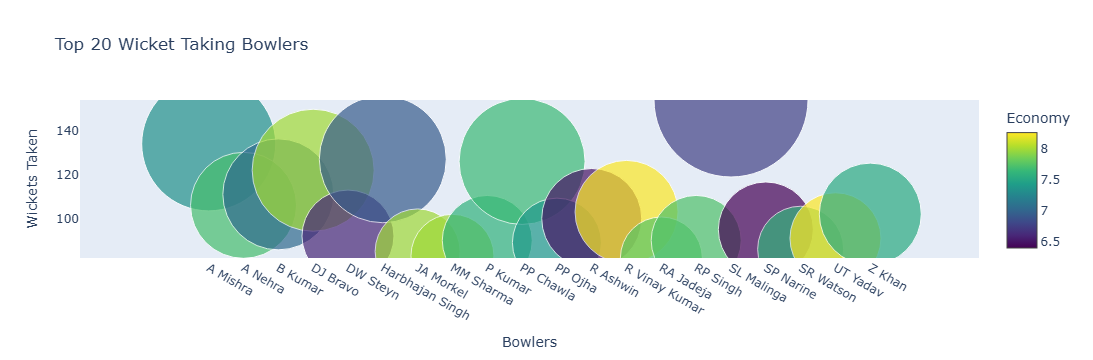

In [100]:
trace = go.Scatter(

    y = bowlers['wickets'],

    x = bowlers['bowler'],

    mode = 'markers',

    marker = dict(

        size = bowlers['wickets'].values,

        color = bowlers['economy'].values,

        colorscale = 'Viridis',

        showscale = True,

        colorbar = dict(title = 'Economy'),

    ),

    text = bowlers['overs'].values

)

data = [trace]

layout = go.Layout(

    autosize = True,

    title = 'Top 20 Wicket Taking Bowlers',

    hovermode = 'closest',

    xaxis = dict(

        showgrid = False,

        zeroline = False,

        showline = False,

        title = 'Bowlers'

    ),

    yaxis = dict(

        title = 'Wickets Taken',

        ticklen = 5,

        gridwidth = 2,

        showgrid = False,

        zeroline = False,

        showline = False

    ),

    showlegend = False

)

fig = go.Figure(data = data, layout = layout)

py.iplot(fig, filename = 'scatterChart')

<h3>Highest Dismissals For a Batsman by a Bowler</h3>

In [109]:
def get_top_bowler(batsman_name):

    batsman_data = deliveries[deliveries['batsman'] == batsman_name]

    batsman_data = batsman_data[batsman_data['dismissal_kind'].isin(
        ['caught', 'lbw', 'bowled', 'stumped', 'caught and bowled', 'hit wicket']
    )]

    batsman_data = batsman_data.groupby('bowler')['dismissal_kind'].count().sort_values(
        ascending = False
    ).head(1).reset_index()

    batsman_data.columns = ['bowler', 'wickets']

    batsman_data['batsman'] = batsman_name

    return batsman_data


batsmen = ['CH Gayle', 'V Kohli', 'SK Raina', 'AB de Villiers',
           'MS Dhoni', 'G Gambhir', 'RG Sharma', 'RV Uthappa',
           'S Dhawan', 'DA Warner']


results = [get_top_bowler(batsman) for batsman in batsmen]

results = pd.concat(results, ignore_index = True)

results

,bowler,wickets,batsman
0,R Ashwin,4,CH Gayle
1,A Nehra,6,V Kohli
2,Harbhajan Singh,5,SK Raina
3,KH Pandya,4,AB de Villiers
4,Z Khan,7,MS Dhoni
5,Z Khan,6,G Gambhir
6,R Vinay Kumar,6,RG Sharma
7,A Mishra,4,RV Uthappa
8,Z Khan,4,S Dhawan
9,L Balaji,3,DA Warner


In [112]:
new = results[['batsman', 'bowler', 'wickets']]

new.columns = ['batsman', 'bowler', 'No_of_Dismissals']

new.head()

,batsman,bowler,No_of_Dismissals
0,CH Gayle,R Ashwin,4
1,V Kohli,A Nehra,6
2,SK Raina,Harbhajan Singh,5
3,AB de Villiers,KH Pandya,4
4,MS Dhoni,Z Khan,7


In [114]:
print(type(results))
print(results.columns)

<class 'pandas.core.frame.DataFrame'>
Index(['bowler', 'wickets', 'batsman'], dtype='object')


<h3>Purple Caps Each Season</h3>

In [120]:
dismissal_kinds = ["bowled", "caught", "lbw", "stumped", "caught and bowled", "hit wicket"]

purple = deliveries.merge(matches, left_on='match_id', right_on='id', how='left')

purple = purple.groupby(['season', 'bowler'])['total_runs'].count().reset_index()

purple.columns = ['season', 'bowler', 'count_wickets']

purple = purple.sort_values('count_wickets', ascending=False)

purple = purple.drop_duplicates('season', keep='first').sort_values(by='season')

purple

,season,bowler,count_wickets
51,2008,MS Gony,371
174,2009,RP Singh,382
210,2010,A Kumble,389
447,2011,SL Malinga,397
554,2012,R Ashwin,402
640,2013,Harbhajan Singh,430
733,2014,AR Patel,403
831,2015,A Nehra,385
939,2016,B Kumar,414
1077,2017,JJ Bumrah,373


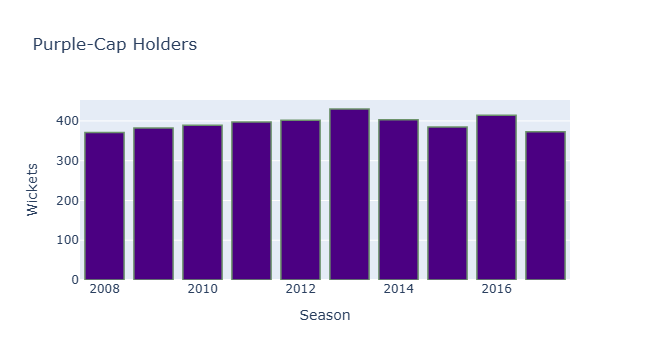

In [122]:
trace1 = go.Bar(
    x = purple['season'].values,
    y = purple['count_wickets'].values,
    name = 'Total Wickets',
    marker = dict(
        color = 'rgb(75, 0, 130)',
        line = dict(
            color = 'rgb(108, 147, 107)',
            width = 1.5
        )
    ),
    opacity = 1
)

layout = go.Layout(
    title = 'Purple-Cap Holders',
    xaxis = dict(title = 'Season'),
    yaxis = dict(title = 'Wickets')
)

data = [trace1]

fig = go.Figure(data = data, layout = layout)

py.iplot(fig, filename = 'stacked-bar')